In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root, len(files))

/kaggle/input 0
/kaggle/input/models 0
/kaggle/input/models/jagannathpr 0
/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint 0
/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint/pytorch 0
/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint/pytorch/default 0
/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint/pytorch/default/1 1
/kaggle/input/datasets 0
/kaggle/input/datasets/nazmulxdxd 0
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification 2
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_test 0
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_test/test 0
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_test/test/mdoscc 0
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_test/test/mdoscc/o-3-00-01 11
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_test/test/mdoscc/o-3-00-02 11
/kaggle/input/datasets/nazmulxdxd/orchid-oscc-

In [3]:
import os

base_path = "/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification"

for split in ["ORCHID_train", "ORCHID_val", "ORCHID_test"]:
    split_path = os.path.join(base_path, split)
    print(f"\n{split}")

    for class_name in sorted(os.listdir(os.path.join(split_path, split.replace("ORCHID_", "").lower()))):
        class_path = os.path.join(split_path, split.replace("ORCHID_", "").lower(), class_name)
        if os.path.isdir(class_path):
            count = sum(
                len(files)
                for _, _, files in os.walk(class_path)
            )
            print(f"{class_name}: {count}")


ORCHID_train
mdoscc: 2699
normal: 1045
osmf: 2095
pdoscc: 1599
wdoscc: 2790

ORCHID_val
mdoscc: 760
normal: 294
osmf: 592
pdoscc: 451
wdoscc: 788

ORCHID_test
mdoscc: 421
normal: 163
osmf: 328
pdoscc: 247
wdoscc: 433


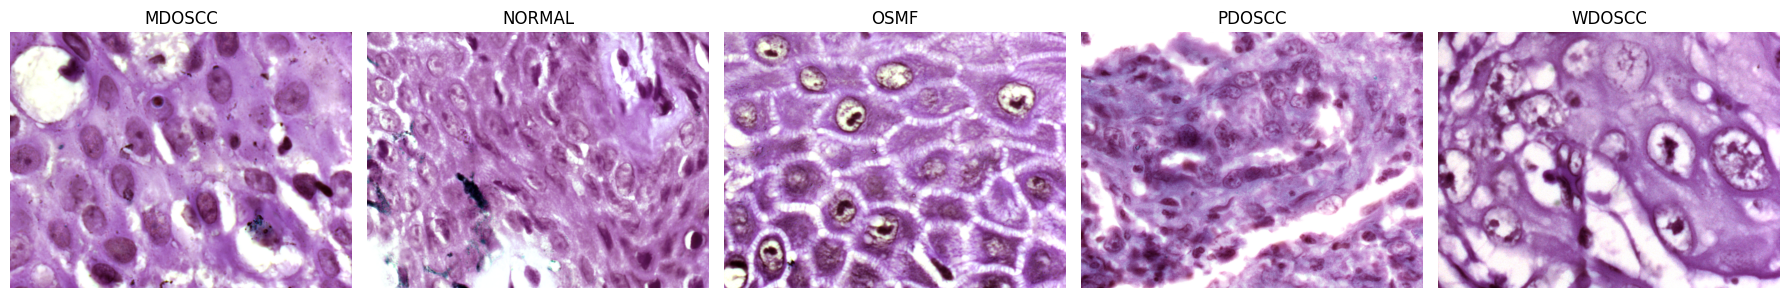

In [4]:

import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification"
class_names = ["mdoscc", "normal", "osmf", "pdoscc", "wdoscc"]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, class_name in zip(axes, class_names):
    class_path = os.path.join(base_path, "ORCHID_train", "train", class_name)

    patient_folders = sorted(os.listdir(class_path))
    image_path = None

    for patient in patient_folders:
        patient_path = os.path.join(class_path, patient)

        if os.path.isdir(patient_path):
            images = [
                f for f in os.listdir(patient_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
            ]
            if images:
                image_path = os.path.join(patient_path, images[0])
                break

        elif patient.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):
            image_path = patient_path
            break

    if image_path:
        image = Image.open(image_path).convert("RGB")
        ax.imshow(image)
        ax.set_title(class_name.upper())
    else:
        ax.set_title(f"{class_name.upper()}\nNo image found")

    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [7]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from collections import Counter

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Dataset paths
BASE_PATH = "/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification"

TRAIN_DIR = os.path.join(BASE_PATH, "ORCHID_train", "train")
VAL_DIR   = os.path.join(BASE_PATH, "ORCHID_val", "val")
TEST_DIR  = os.path.join(BASE_PATH, "ORCHID_test", "test")

# Training configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 5
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Training path exists:", os.path.isdir(TRAIN_DIR))
print("Validation path exists:", os.path.isdir(VAL_DIR))
print("Test path exists:", os.path.isdir(TEST_DIR))


Device: cuda
Training path exists: True
Validation path exists: True
Test path exists: True


In [8]:

from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations ready.")
print("Validation/test transformations ready.")
print("Image size:", IMAGE_SIZE)


Training transformations ready.
Validation/test transformations ready.
Image size: 224


In [9]:

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transforms
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transforms
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transforms
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("\nClass-to-index mapping:")
print(train_dataset.class_to_idx)


Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Training images: 10228
Validation images: 2885
Testing images: 1592

Class-to-index mapping:
{'mdoscc': 0, 'normal': 1, 'osmf': 2, 'pdoscc': 3, 'wdoscc': 4}


In [10]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 320
Validation batches: 91
Testing batches: 50


In [11]:

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNetB0 weights
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze the pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace the final layer for our five classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

# Move model to GPU
model = model.to(DEVICE)

print("Model: EfficientNetB0")
print("Number of classes:", NUM_CLASSES)
print("Device:", DEVICE)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 151MB/s]


Model: EfficientNetB0
Number of classes: 5
Device: cuda
Trainable parameters: 6405


In [12]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")


Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001


In [12]:

import copy
import time

EPOCHS = 5
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    start_time = time.time()

    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, "/kaggle/working/best_efficientnet_b0.pth")

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed / 60:.1f} min"
    )

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")
print("Best checkpoint saved.")


Epoch 1/5 | Train Loss: 1.0583 | Train Acc: 0.5704 | Val Loss: 0.8890 | Val Acc: 0.6562 | Time: 9.3 min
Epoch 2/5 | Train Loss: 0.9090 | Train Acc: 0.6336 | Val Loss: 0.8176 | Val Acc: 0.6704 | Time: 9.1 min
Epoch 3/5 | Train Loss: 0.8669 | Train Acc: 0.6480 | Val Loss: 0.7985 | Val Acc: 0.6766 | Time: 9.0 min
Epoch 4/5 | Train Loss: 0.8427 | Train Acc: 0.6586 | Val Loss: 0.7672 | Val Acc: 0.6925 | Time: 9.0 min
Epoch 5/5 | Train Loss: 0.8295 | Train Acc: 0.6666 | Val Loss: 0.7583 | Val Acc: 0.6929 | Time: 8.9 min

Best validation loss: 0.7583
Best checkpoint saved.


In [13]:
checkpoint_path = "/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint/pytorch/default/1/best_efficientnet_b0.pth"

model.load_state_dict(torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
))

model.eval()

print("Previous EfficientNet-B0 model restored successfully.")

Previous EfficientNet-B0 model restored successfully.


In [14]:
import os


if os.path.exists(checkpoint_path):
    size_mb = os.path.getsize(checkpoint_path) / (1024 * 1024)
    print("Checkpoint exists:", True)
    print(f"Checkpoint size: {size_mb:.2f} MB")
    print("Ready to reuse without retraining.")
else:
    print("Checkpoint not found. We need to investigate before continuing.")

Checkpoint exists: True
Checkpoint size: 15.60 MB
Ready to reuse without retraining.


In [13]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import torch


all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

print(f"Validation accuracy: {accuracy_score(all_labels, all_predictions):.4f}")
print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=train_dataset.classes,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(all_labels, all_predictions))

Validation accuracy: 0.6929

Classification report:
              precision    recall  f1-score   support

      mdoscc     0.5984    0.5803    0.5892       760
      normal     0.7682    0.7891    0.7785       294
        osmf     0.8013    0.8649    0.8318       592
      pdoscc     0.6498    0.6829    0.6659       451
      wdoscc     0.6903    0.6421    0.6654       788

    accuracy                         0.6929      2885
   macro avg     0.7016    0.7119    0.7062      2885
weighted avg     0.6905    0.6929    0.6911      2885

Confusion matrix:
[[441  15  23 105 176]
 [ 11 232  43   2   6]
 [ 20  39 512   6  15]
 [ 92   4  17 308  30]
 [173  12  44  53 506]]


In [14]:
import os
from collections import Counter

def get_image_names(folder):
    return Counter(
        filename
        for _, _, files in os.walk(folder)
        for filename in files
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"))
    )

train_names = get_image_names(TRAIN_DIR)
val_names = get_image_names(VAL_DIR)
test_names = get_image_names(TEST_DIR)

print("Train-validation filename overlaps:", sum((train_names & val_names).values()))
print("Train-test filename overlaps:", sum((train_names & test_names).values()))
print("Validation-test filename overlaps:", sum((val_names & test_names).values()))

Train-validation filename overlaps: 0
Train-test filename overlaps: 0
Validation-test filename overlaps: 0


In [18]:
import os
import hashlib

def get_image_hashes(folder):
    hashes = {}

    for root, _, files in os.walk(folder):
        for filename in files:
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
            ):
                path = os.path.join(root, filename)

                with open(path, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                hashes.setdefault(file_hash, []).append(path)

    return hashes

train_hashes = get_image_hashes(TRAIN_DIR)
val_hashes = get_image_hashes(VAL_DIR)
test_hashes = get_image_hashes(TEST_DIR)

train_set = set(train_hashes)
val_set = set(val_hashes)
test_set = set(test_hashes)

print("Exact duplicates: train vs validation:", len(train_set & val_set))
print("Exact duplicates: train vs test:", len(train_set & test_set))
print("Exact duplicates: validation vs test:", len(val_set & test_set))

KeyboardInterrupt: 

In [22]:
def show_overlaps(hashes_a, hashes_b, name_a, name_b):
    common_hashes = set(hashes_a) & set(hashes_b)

    print(f"\n{name_a} vs {name_b}: {len(common_hashes)} matching hashes")

    for file_hash in sorted(common_hashes):
        for path_a in hashes_a[file_hash]:
            for path_b in hashes_b[file_hash]:
                class_a = os.path.basename(os.path.dirname(path_a))
                class_b = os.path.basename(os.path.dirname(path_b))

                print(f"{class_a} | {class_b}")
                print(" ", path_a)
                print(" ", path_b)

show_overlaps(train_hashes, val_hashes, "Train", "Validation")
show_overlaps(train_hashes, test_hashes, "Train", "Test")
show_overlaps(val_hashes, test_hashes, "Validation", "Test")


Train vs Validation: 35 matching hashes
o-3-00-06 | o-2-00-13
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-022.png
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_val/val/wdoscc/o-2-00-13/o-2-00-13-029.png
o-2-00-12 | o-3-00-05
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/wdoscc/o-2-00-12/o-2-00-12-017.png
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_val/val/mdoscc/o-3-00-05/o-3-00-05-017.png
o-3-00-05 | o-2-00-12
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-05/o-3-00-05-053.png
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_val/val/wdoscc/o-2-00-12/o-2-00-12-053.png
o-3-00-06 | o-2-00-13
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-047.png
  /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/O

In [18]:
import os

groups = ["o-3-00-05", "o-2-00-12", "o-3-00-06", "o-2-00-13"]
splits = {
    "train": TRAIN_DIR,
    "validation": VAL_DIR,
    "test": TEST_DIR
}

for split_name, split_dir in splits.items():
    print(f"\n{split_name.upper()}")

    for group in groups:
        matches = []

        for root, dirs, files in os.walk(split_dir):
            if os.path.basename(root) == group:
                count = sum(
                    f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"))
                    for f in files
                )
                matches.append((os.path.relpath(root, split_dir), count))

        print(group, matches)


TRAIN
o-3-00-05 [('mdoscc/o-3-00-05', 72)]
o-2-00-12 [('wdoscc/o-2-00-12', 72)]
o-3-00-06 [('mdoscc/o-3-00-06', 35)]
o-2-00-13 [('wdoscc/o-2-00-13', 35)]

VALIDATION
o-3-00-05 [('mdoscc/o-3-00-05', 20)]
o-2-00-12 [('wdoscc/o-2-00-12', 20)]
o-3-00-06 [('mdoscc/o-3-00-06', 10)]
o-2-00-13 [('wdoscc/o-2-00-13', 10)]

TEST
o-3-00-05 [('mdoscc/o-3-00-05', 11)]
o-2-00-12 [('wdoscc/o-2-00-12', 11)]
o-3-00-06 [('mdoscc/o-3-00-06', 5)]
o-2-00-13 [('wdoscc/o-2-00-13', 5)]


In [27]:
all_hash_maps = {
    "train": train_hashes,
    "validation": val_hashes,
    "test": test_hashes
}

split_dirs = {
    "train": TRAIN_DIR,
    "validation": VAL_DIR,
    "test": TEST_DIR
}

all_records = {}

for split_name, hash_map in all_hash_maps.items():
    for file_hash, paths in hash_map.items():
        for path in paths:
            class_name = os.path.relpath(
                path, split_dirs[split_name]
            ).split(os.sep)[0]

            all_records.setdefault(file_hash, []).append(
                (split_name, class_name, path)
            )

duplicate_groups = {
    file_hash: records
    for file_hash, records in all_records.items()
    if len(records) > 1
}

conflicting_labels = {
    file_hash: records
    for file_hash, records in duplicate_groups.items()
    if len(set(record[1] for record in records)) > 1
}

print("Duplicate hash groups:", len(duplicate_groups))
print("Groups with conflicting labels:", len(conflicting_labels))
print("Groups spanning multiple splits:", sum(
    len(set(record[0] for record in records)) > 1
    for records in duplicate_groups.values()
))

for records in list(conflicting_labels.values())[:5]:
    print()
    for split_name, class_name, path in records:
        print(split_name, "|", class_name, "|", path)

NameError: name 'train_hashes' is not defined

In [25]:
print("Conflicting duplicate groups:", len(conflicting_labels))

for records in list(conflicting_labels.values())[:10]:
    print("\n---")
    for split_name, class_name, path in records:
        print(f"{split_name} | {class_name} | {path}")

Conflicting duplicate groups: 153

---
train | mdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-015.png
train | wdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/wdoscc/o-2-00-13/o-2-00-13-021.png

---
train | mdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-008.png
train | wdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/wdoscc/o-2-00-13/o-2-00-13-016.png

---
train | mdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-027.png
train | wdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/wdoscc/o-2-00-13/o-2-00-13-033.png

---
train | mdoscc | /kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification/ORCHID_train/train/mdoscc/o-3-00-06/o-3-00-06-031.png
validation | wdoscc | 

In [26]:
from collections import Counter

class_pairs = Counter()
split_pairs = Counter()
records_per_group = Counter()

for records in conflicting_labels.values():
    classes = tuple(sorted(set(r[1] for r in records)))
    splits = tuple(sorted(set(r[0] for r in records)))

    class_pairs[classes] += 1
    split_pairs[splits] += 1
    records_per_group[len(records)] += 1

print("Duplicate groups by class combination:")
for key, count in class_pairs.items():
    print(key, ":", count)

print("\nDuplicate groups by split combination:")
for key, count in split_pairs.items():
    print(key, ":", count)

print("\nNumber of records per duplicate group:")
for key, count in sorted(records_per_group.items()):
    print(key, "records:", count, "groups")

Duplicate groups by class combination:
('mdoscc', 'wdoscc') : 153

Duplicate groups by split combination:
('train',) : 78
('train', 'validation') : 35
('test', 'train') : 23
('validation',) : 11
('test', 'validation') : 3
('test',) : 3

Number of records per duplicate group:
2 records: 153 groups


In [20]:
from collections import Counter
import os

folder_pairs = Counter()

for records in conflicting_labels.values():
    folders = []

    for split_name, class_name, path in records:
        relative_path = os.path.relpath(path, split_dirs[split_name])
        parts = relative_path.split(os.sep)
        folders.append((class_name, parts[1]))

    folder_pairs[tuple(sorted(folders))] += 1

print("Distinct folder pairs:", len(folder_pairs))

for pair, count in folder_pairs.most_common(20):
    print(pair, "| identical images:", count)

NameError: name 'conflicting_labels' is not defined

In [15]:
from torch.utils.data import Subset, DataLoader
from collections import Counter
import os

affected_folders = {
    "o-3-00-05",
    "o-2-00-12",
    "o-3-00-06",
    "o-2-00-13"
}

def clean_indices(dataset):
    return [
        i for i, (path, label) in enumerate(dataset.samples)
        if os.path.basename(os.path.dirname(path)) not in affected_folders
    ]

train_indices = clean_indices(train_dataset)
val_indices = clean_indices(val_dataset)
test_indices = clean_indices(test_dataset)

clean_train = Subset(train_dataset, train_indices)
clean_val = Subset(val_dataset, val_indices)
clean_test = Subset(test_dataset, test_indices)

print("Original images:", len(train_dataset) + len(val_dataset) + len(test_dataset))
print("Retained images:", len(clean_train) + len(clean_val) + len(clean_test))
print("Excluded images:", 
      len(train_dataset) + len(val_dataset) + len(test_dataset)
      - len(clean_train) - len(clean_val) - len(clean_test))

print("\nRetained by split:")
print("Train:", len(clean_train))
print("Validation:", len(clean_val))
print("Test:", len(clean_test))

clean_train_loader = DataLoader(
    clean_train, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

clean_val_loader = DataLoader(
    clean_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

clean_test_loader = DataLoader(
    clean_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

Original images: 14705
Retained images: 14399
Excluded images: 306

Retained by split:
Train: 10014
Validation: 2825
Test: 1560


In [20]:
clean_hashes = {
    "train": {
        train_hashes[h]
        for h in []
    }
}

def retained_hash_set(dataset, indices, original_hashes):
    retained_paths = {
        dataset.samples[i][0] for i in indices
    }

    return {
        file_hash
        for file_hash, paths in original_hashes.items()
        if any(path in retained_paths for path in paths)
    }

clean_train_hashes = retained_hash_set(
    train_dataset, train_indices, train_hashes
)
clean_val_hashes = retained_hash_set(
    val_dataset, val_indices, val_hashes
)
clean_test_hashes = retained_hash_set(
    test_dataset, test_indices, test_hashes
)

print("Train vs validation:", len(clean_train_hashes & clean_val_hashes))
print("Train vs test:", len(clean_train_hashes & clean_test_hashes))
print("Validation vs test:", len(clean_val_hashes & clean_test_hashes))

NameError: name 'train_hashes' is not defined

In [33]:
from collections import Counter

def retained_class_counts(dataset, indices):
    return Counter(dataset.classes[dataset.samples[i][1]] for i in indices)

print("Training class counts:")
print(dict(retained_class_counts(train_dataset, train_indices)))

print("\nValidation class counts:")
print(dict(retained_class_counts(val_dataset, val_indices)))

print("\nTest class counts:")
print(dict(retained_class_counts(test_dataset, test_indices)))

Training class counts:
{'mdoscc': 2592, 'normal': 1045, 'osmf': 2095, 'pdoscc': 1599, 'wdoscc': 2683}

Validation class counts:
{'mdoscc': 730, 'normal': 294, 'osmf': 592, 'pdoscc': 451, 'wdoscc': 758}

Test class counts:
{'mdoscc': 405, 'normal': 163, 'osmf': 328, 'pdoscc': 247, 'wdoscc': 417}


In [15]:
import os
from torch.utils.data import Subset

affected_folders = {
    "o-3-00-05",
    "o-2-00-12",
    "o-3-00-06",
    "o-2-00-13"
}

def clean_indices(dataset):
    return [
        i for i, (path, label) in enumerate(dataset.samples)
        if os.path.basename(os.path.dirname(path)) not in affected_folders
    ]

train_indices = clean_indices(train_dataset)
val_indices = clean_indices(val_dataset)
test_indices = clean_indices(test_dataset)

clean_train = Subset(train_dataset, train_indices)
clean_val = Subset(val_dataset, val_indices)
clean_test = Subset(test_dataset, test_indices)

print("Training:", len(clean_train))
print("Validation:", len(clean_val))
print("Testing:", len(clean_test))

Training: 10014
Validation: 2825
Testing: 1560


In [16]:
from torch.utils.data import DataLoader

clean_train_loader = DataLoader(
    clean_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

clean_val_loader = DataLoader(
    clean_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

clean_test_loader = DataLoader(
    clean_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

In [38]:

import os
import time
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# 1. Configure data loaders
NUM_WORKERS = 4

clean_train_loader = DataLoader(
    clean_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

clean_val_loader = DataLoader(
    clean_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# 2. Initialize EfficientNet-B0 with ImageNet pretrained weights
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze the feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace the classifier for five classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Training images:", len(clean_train))
print("Validation images:", len(clean_val))
print("Training batches:", len(clean_train_loader))
print("Validation batches:", len(clean_val_loader))

# 3. Train and validate
EPOCHS = 5
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

checkpoint_path = "/kaggle/working/best_efficientnet_b0_clean.pth"

for epoch in range(EPOCHS):
    epoch_start = time.time()

    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(clean_train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(clean_train_loader)}"
            )

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in clean_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, checkpoint_path)

    elapsed = (time.time() - epoch_start) / 60

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} completed | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed:.2f} min\n"
    )

# 4. Restore the best validation checkpoint in memory
model.load_state_dict(best_model_state)

print("Training complete.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best validation accuracy: {max(history['val_acc']):.4f}")
print("Best checkpoint:", checkpoint_path)


Device: cuda
GPU: Tesla T4
Training images: 10014
Validation images: 2825
Training batches: 313
Validation batches: 89
Epoch 1/5 | Batch 50/313
Epoch 1/5 | Batch 100/313
Epoch 1/5 | Batch 150/313
Epoch 1/5 | Batch 200/313
Epoch 1/5 | Batch 250/313
Epoch 1/5 | Batch 300/313

Epoch 1/5 completed | Train Loss: 1.0477 | Train Acc: 0.5783 | Val Loss: 0.8699 | Val Acc: 0.6542 | Time: 12.45 min

Epoch 2/5 | Batch 50/313
Epoch 2/5 | Batch 100/313
Epoch 2/5 | Batch 150/313
Epoch 2/5 | Batch 200/313
Epoch 2/5 | Batch 250/313
Epoch 2/5 | Batch 300/313

Epoch 2/5 completed | Train Loss: 0.8868 | Train Acc: 0.6359 | Val Loss: 0.8059 | Val Acc: 0.6747 | Time: 12.16 min

Epoch 3/5 | Batch 50/313
Epoch 3/5 | Batch 100/313
Epoch 3/5 | Batch 150/313
Epoch 3/5 | Batch 200/313
Epoch 3/5 | Batch 250/313
Epoch 3/5 | Batch 300/313

Epoch 3/5 completed | Train Loss: 0.8471 | Train Acc: 0.6599 | Val Loss: 0.7670 | Val Acc: 0.6920 | Time: 12.31 min

Epoch 4/5 | Batch 50/313
Epoch 4/5 | Batch 100/313
Epoch 4/5 |

In [17]:
import os

DATASET_DIR = "/kaggle/input/datasets/nazmulxdxd/orchid-oscc-classification"

TRAIN_DIR = os.path.join(DATASET_DIR, "ORCHID_train", "train")
VAL_DIR = os.path.join(DATASET_DIR, "ORCHID_val", "val")
TEST_DIR = os.path.join(DATASET_DIR, "ORCHID_test", "test")

for name, path in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)
]:
    print(f"{name}: {os.path.exists(path)}")
    if os.path.exists(path):
        print("  Classes:", sorted(os.listdir(path)))

Train: True
  Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Validation: True
  Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Test: True
  Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


In [18]:
import os
from torch.utils.data import Subset
from torchvision import datasets, transforms

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
val_dataset = datasets.ImageFolder(
    VAL_DIR, transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

affected_folders = {
    "o-3-00-05",
    "o-2-00-12",
    "o-3-00-06",
    "o-2-00-13"
}

def clean_indices(dataset):
    return [
        i for i, (path, label) in enumerate(dataset.samples)
        if os.path.basename(os.path.dirname(path))
        not in affected_folders
    ]

train_indices = clean_indices(train_dataset)
val_indices = clean_indices(val_dataset)
test_indices = clean_indices(test_dataset)

clean_train = Subset(train_dataset, train_indices)
clean_val = Subset(val_dataset, val_indices)
clean_test = Subset(test_dataset, test_indices)

print("Classes:", train_dataset.classes)
print("Training images:", len(clean_train))
print("Validation images:", len(clean_val))
print("Test images:", len(clean_test))
print("Total retained:", len(clean_train) + len(clean_val) + len(clean_test))

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Training images: 10014
Validation images: 2825
Test images: 1560
Total retained: 14399


In [19]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 4

clean_train_loader = DataLoader(
    clean_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

clean_val_loader = DataLoader(
    clean_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

clean_test_loader = DataLoader(
    clean_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

print("Training batches:", len(clean_train_loader))
print("Validation batches:", len(clean_val_loader))
print("Test batches:", len(clean_test_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 313
Validation batches: 89
Test batches: 49
Batch size: 32


In [20]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 5

weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

for param in model.features.parameters():
    param.requires_grad = False

for param in model.features[8].parameters():
    param.requires_grad = True

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam([
    {
        "params": model.features[8].parameters(),
        "lr": 0.00001
    },
    {
        "params": model.classifier.parameters(),
        "lr": 0.0001
    }
])

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Architecture: EfficientNet-B0")
print("Trainable feature block: features[8]")
print("Trainable classifier: Yes")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cuda
GPU: Tesla T4
Architecture: EfficientNet-B0
Trainable feature block: features[8]
Trainable classifier: Yes
Trainable parameters: 418565


In [21]:
import time
import copy
import torch

EPOCHS = 5
best_val_acc = 0.0
best_val_loss = float("inf")
best_model_state = None

checkpoint_path = "/kaggle/working/best_efficientnet_b0_finetuned.pth"

for epoch in range(EPOCHS):
    start_time = time.time()

    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(clean_train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(clean_train_loader)}",
                flush=True
            )

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in clean_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_model_state,
            "class_names": train_dataset.classes,
            "epoch": epoch + 1,
            "val_accuracy": best_val_acc,
            "val_loss": best_val_loss
        }, checkpoint_path)

        print("Best checkpoint saved.", flush=True)

    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch {epoch + 1}/{EPOCHS} completed | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed:.2f} min",
        flush=True
    )

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Best checkpoint:", checkpoint_path)

KeyboardInterrupt: 

Validation Classification Report:

              precision    recall  f1-score   support

      mdoscc     0.6099    0.4219    0.4988       730
      normal     0.8028    0.5816    0.6746       294
        osmf     0.7079    0.8885    0.7880       592
      pdoscc     0.5822    0.7694    0.6628       451
      wdoscc     0.6445    0.6530    0.6488       758

    accuracy                         0.6538      2825
   macro avg     0.6695    0.6629    0.6546      2825
weighted avg     0.6554    0.6538    0.6441      2825



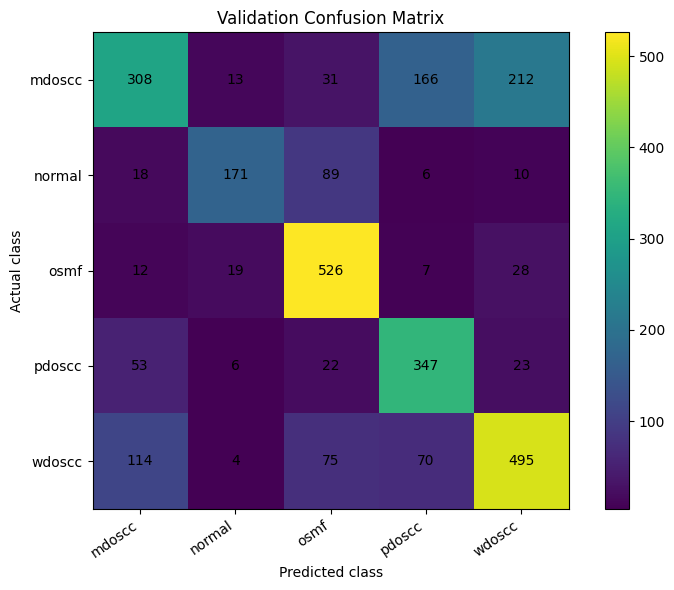

In [28]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in clean_val_loader:
        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

class_names = train_dataset.classes

print("Validation Classification Report:\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, interpolation="nearest")
ax.figure.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Validation Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()


In [23]:

import numpy as np
import torch
import torch.nn as nn

class_names = train_dataset.classes
num_classes = len(class_names)

clean_train_labels = [
    train_dataset.targets[i] for i in train_indices
]

class_counts = np.bincount(
    clean_train_labels,
    minlength=num_classes
)

class_weights = len(clean_train_labels) / (
    num_classes * class_counts
)

print("Class counts in cleaned training set:")
for name, count, weight in zip(
    class_names, class_counts, class_weights
):
    print(f"{name}: {count} images | weight: {weight:.4f}")

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nClass weights ready:", class_weights)


Class counts in cleaned training set:
mdoscc: 2592 images | weight: 0.7727
normal: 1045 images | weight: 1.9166
osmf: 2095 images | weight: 0.9560
pdoscc: 1599 images | weight: 1.2525
wdoscc: 2683 images | weight: 0.7465

Class weights ready: tensor([0.7727, 1.9166, 0.9560, 1.2525, 0.7465], device='cuda:0')


In [24]:

import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = len(class_names)

weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

for param in model.features.parameters():
    param.requires_grad = False

for param in model.features[8].parameters():
    param.requires_grad = True

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam([
    {"params": model.features[8].parameters(), "lr": 0.00001},
    {"params": model.classifier.parameters(), "lr": 0.0001}
])

print("Device:", DEVICE)
print("Architecture: EfficientNet-B0")
print("Trainable feature block: features[8]")
print("Loss: Class-weighted CrossEntropyLoss")
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


Device: cuda
Architecture: EfficientNet-B0
Trainable feature block: features[8]
Loss: Class-weighted CrossEntropyLoss
Trainable parameters: 418565


In [31]:

import time
import copy
import torch
from sklearn.metrics import f1_score

EPOCHS = 5
best_val_f1 = -1.0
best_val_acc = 0.0
best_val_loss = float("inf")

checkpoint_path = "/kaggle/working/best_efficientnet_b0_weighted.pth"

for epoch in range(EPOCHS):
    start_time = time.time()

    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(clean_train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(clean_train_loader)}",
                flush=True
            )

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in clean_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_acc = val_acc
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "class_names": class_names,
            "epoch": epoch + 1,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "val_loss": val_loss
        }, checkpoint_path)

        print("Best macro-F1 checkpoint saved.", flush=True)

    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch {epoch + 1}/{EPOCHS} completed | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"Time: {elapsed:.2f} min",
        flush=True
    )

print("\nTraining complete.")
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print(f"Accuracy at best macro-F1: {best_val_acc:.4f}")
print(f"Validation loss at best macro-F1: {best_val_loss:.4f}")
print("Best checkpoint:", checkpoint_path)


Epoch 1/5 | Batch 50/313
Epoch 1/5 | Batch 100/313
Epoch 1/5 | Batch 150/313
Epoch 1/5 | Batch 200/313
Epoch 1/5 | Batch 250/313
Epoch 1/5 | Batch 300/313
Best macro-F1 checkpoint saved.
Epoch 1/5 completed | Train Loss: 1.3834 | Train Acc: 0.4536 | Val Loss: 1.2227 | Val Acc: 0.5462 | Val Macro-F1: 0.5411 | Time: 14.74 min
Epoch 2/5 | Batch 50/313
Epoch 2/5 | Batch 100/313
Epoch 2/5 | Batch 150/313
Epoch 2/5 | Batch 200/313
Epoch 2/5 | Batch 250/313
Epoch 2/5 | Batch 300/313
Best macro-F1 checkpoint saved.
Epoch 2/5 completed | Train Loss: 1.1353 | Train Acc: 0.5626 | Val Loss: 1.0901 | Val Acc: 0.5639 | Val Macro-F1: 0.5554 | Time: 14.26 min
Epoch 3/5 | Batch 50/313
Epoch 3/5 | Batch 100/313
Epoch 3/5 | Batch 150/313
Epoch 3/5 | Batch 200/313
Epoch 3/5 | Batch 250/313
Epoch 3/5 | Batch 300/313
Best macro-F1 checkpoint saved.
Epoch 3/5 completed | Train Loss: 1.0252 | Train Acc: 0.5834 | Val Loss: 1.0126 | Val Acc: 0.5809 | Val Macro-F1: 0.5785 | Time: 14.24 min
Epoch 4/5 | Batch 50/3

In [25]:

import torch

checkpoint_path = "/kaggle/working/best_efficientnet_b0_weighted.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best weighted checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Validation accuracy:", checkpoint["val_accuracy"])
print("Validation macro-F1:", checkpoint["val_macro_f1"])


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/best_efficientnet_b0_weighted.pth'

Weighted Model - Validation Classification Report:

              precision    recall  f1-score   support

      mdoscc     0.6147    0.2973    0.4007       730
      normal     0.6000    0.7551    0.6687       294
        osmf     0.7292    0.8142    0.7694       592
      pdoscc     0.4680    0.8426    0.6017       451
      wdoscc     0.6948    0.5765    0.6301       758

    accuracy                         0.6152      2825
   macro avg     0.6213    0.6571    0.6141      2825
weighted avg     0.6352    0.6152    0.5995      2825



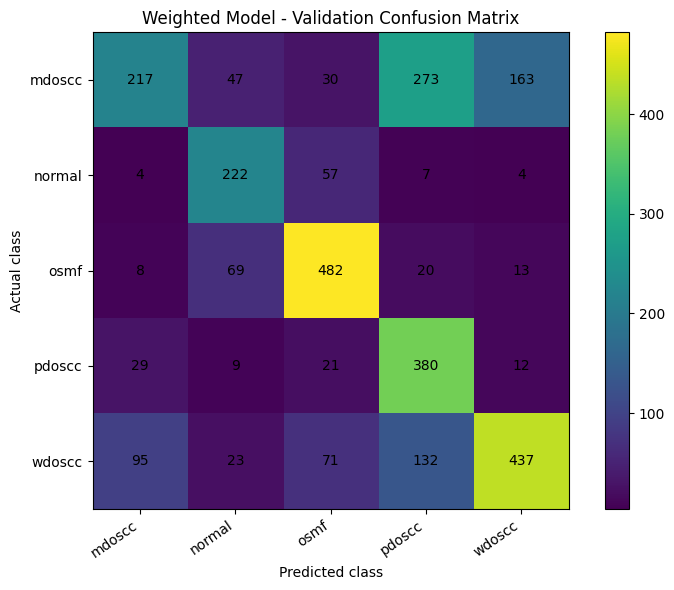

In [33]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in clean_val_loader:
        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

class_names = train_dataset.classes

print("Weighted Model - Validation Classification Report:\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, interpolation="nearest")
ax.figure.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Weighted Model - Validation Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()



In [26]:

import torch
import torch.nn as nn
from torchvision import models

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)

for param in model.features.parameters():
    param.requires_grad = False

for param in model.features[7].parameters():
    param.requires_grad = True

for param in model.features[8].parameters():
    param.requires_grad = True

model = model.to(DEVICE)

print("Model:", "EfficientNet-B0")
print("Trainable feature blocks: 7 and 8")
print("Trainable classifier: yes")
print("Device:", DEVICE)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


Model: EfficientNet-B0
Trainable feature blocks: 7 and 8
Trainable classifier: yes
Device: cuda
Trainable parameters: 1135797


In [27]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam([
    {
        "params": model.features[7].parameters(),
        "lr": 5e-6
    },
    {
        "params": model.features[8].parameters(),
        "lr": 1e-5
    },
    {
        "params": model.classifier.parameters(),
        "lr": 1e-4
    }
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

print("Unweighted loss:", criterion)
print("Optimizer: Adam")
print("Scheduler: ReduceLROnPlateau")


Unweighted loss: CrossEntropyLoss()
Optimizer: Adam
Scheduler: ReduceLROnPlateau


In [ ]:

import os
import time
import copy
from sklearn.metrics import f1_score

EPOCHS = 5
BEST_PATH = "/kaggle/working/best_efficientnet_b0_blocks7_8.pth"

best_val_f1 = -1.0
best_epoch = 0
history = []

for epoch in range(EPOCHS):
    start_time = time.time()

    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in clean_train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in clean_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(predictions.cpu().numpy())

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total
    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    scheduler.step(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "val_loss": val_loss
        }, BEST_PATH)

    elapsed = (time.time() - start_time) / 60

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Macro-F1: {val_f1:.4f} | "
        f"Time: {elapsed:.2f} min"
    )

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print("Checkpoint:", BEST_PATH)


Epoch 1/5 | Train Loss: 1.3629 | Train Acc: 0.4349 | Val Loss: 1.1617 | Val Acc: 0.5834 | Macro-F1: 0.5535 | Time: 12.98 min
Epoch 2/5 | Train Loss: 1.0990 | Train Acc: 0.5741 | Val Loss: 0.9922 | Val Acc: 0.6212 | Macro-F1: 0.6092 | Time: 13.34 min
Epoch 3/5 | Train Loss: 0.9852 | Train Acc: 0.6149 | Val Loss: 0.9069 | Val Acc: 0.6442 | Macro-F1: 0.6432 | Time: 14.93 min


In [28]:

import torch
import torch.nn as nn
from torchvision import models

model = models.efficientnet_b0(weights=None)

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)

state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict)
model = model.to(DEVICE)
model.eval()

print("Checkpoint loaded successfully.")
print("Architecture: EfficientNet-B0")
print("Number of classes:", model.classifier[1].out_features)
print("Device:", DEVICE)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/best_efficientnet_b0_weighted.pth'

In [29]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

all_labels = []
all_predictions = []
total_loss = 0.0
total_correct = 0
total_samples = 0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in clean_val_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_correct += (predictions == labels).sum().item()
        total_samples += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

val_accuracy = total_correct / total_samples
val_loss = total_loss / total_samples
class_names = train_dataset.classes

print(f"Validation accuracy: {val_accuracy:.4%}")
print(f"Validation loss: {val_loss:.4f}")
print("\nClassification report:\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, interpolation="nearest")
ax.figure.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Restored Checkpoint - Validation Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()


RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

In [34]:

import os
import shutil

checkpoint_copy = "/kaggle/working/orchid_efficientnet_b0_validated.pth"

shutil.copy2(checkpoint_path, checkpoint_copy)

print("Checkpoint copied:", os.path.isfile(checkpoint_copy))
print(
    "Copy size:",
    round(os.path.getsize(checkpoint_copy) / (1024 * 1024), 2),
    "MB"
)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/best_efficientnet_b0_weighted.pth'

In [30]:

print("Device:", DEVICE)
print("Classes:", train_dataset.classes)
print("Training samples:", len(clean_train))
print("Validation samples:", len(clean_val))
print("Test samples:", len(clean_test))
print("Batch size:", clean_train_loader.batch_size)

print("\nModel architecture:")
print(model)

print("\nCurrent validation checkpoint:")
print(checkpoint_copy)


Device: cuda
Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Training samples: 10014
Validation samples: 2825
Test samples: 1560
Batch size: 32

Model architecture:
EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2

NameError: name 'checkpoint_copy' is not defined

In [31]:

import torch

model.eval()

images, labels = next(iter(clean_val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    outputs = model(images)
    probabilities = torch.softmax(outputs, dim=1)
    confidences, predictions = probabilities.max(dim=1)

class_names = train_dataset.classes

for i in range(min(12, len(labels))):
    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]
    confidence = confidences[i].item() * 100

    print(
        f"Image {i + 1:02d} | "
        f"Actual: {actual:8s} | "
        f"Predicted: {predicted:8s} | "
        f"Confidence: {confidence:.2f}%"
    )


RuntimeError: DataLoader worker (pid(s) 150, 151, 152, 153) exited unexpectedly

In [32]:

import os

print("Current best exists:", os.path.isfile(checkpoint_copy))
print(
    "Current best size (MB):",
    round(os.path.getsize(checkpoint_copy) / (1024 * 1024), 2)
    if os.path.isfile(checkpoint_copy) else "Missing"
)


NameError: name 'checkpoint_copy' is not defined

In [33]:

import copy
import torch
import torch.nn as nn
from torchvision import models

# Create a separate model so the current best remains untouched.
experiment_model = models.efficientnet_b0(weights=None)
experiment_model.classifier[1] = nn.Linear(
    experiment_model.classifier[1].in_features, 5
)

saved_state = torch.load(
    checkpoint_copy,
    map_location="cpu",
    weights_only=True
)
experiment_model.load_state_dict(saved_state)

# Freeze every feature block first.
for param in experiment_model.features.parameters():
    param.requires_grad = False

# Fine-tune only the final two feature blocks.
for block_index in [7, 8]:
    for param in experiment_model.features[block_index].parameters():
        param.requires_grad = True

# Keep the classifier trainable.
for param in experiment_model.classifier.parameters():
    param.requires_grad = True

experiment_model = experiment_model.to(DEVICE)

optimizer = torch.optim.Adam([
    {
        "params": experiment_model.features[7].parameters(),
        "lr": 5e-6
    },
    {
        "params": experiment_model.features[8].parameters(),
        "lr": 1e-5
    },
    {
        "params": experiment_model.classifier.parameters(),
        "lr": 1e-4
    }
])

criterion = nn.CrossEntropyLoss()

trainable_params = sum(
    p.numel() for p in experiment_model.parameters()
    if p.requires_grad
)

print("Experiment model prepared.")
print("Trainable parameters:", f"{trainable_params:,}")
print("Current best checkpoint unchanged:", checkpoint_copy)


NameError: name 'checkpoint_copy' is not defined

In [35]:

import os
import time
import numpy as np
import torch
from sklearn.metrics import f1_score, accuracy_score

recovery_path = "/kaggle/working/orchid_experiment_recovery.pth"
experiment_best_path = "/kaggle/working/orchid_experiment_best.pth"

best_macro_f1 = -1.0
best_accuracy = -1.0
history = []

for epoch in range(1, 6):
    start_time = time.time()
    experiment_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in clean_train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = experiment_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    experiment_model.eval()
    val_labels = []
    val_predictions = []
    val_loss_sum = 0.0
    val_total = 0

    with torch.no_grad():
        for images, labels in clean_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = experiment_model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(1)

            val_loss_sum += loss.item() * labels.size(0)
            val_total += labels.size(0)
            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(val_labels, val_predictions)
    val_macro_f1 = f1_score(
        val_labels, val_predictions, average="macro"
    )

    improved = (
        val_macro_f1 > best_macro_f1
        or (
            np.isclose(val_macro_f1, best_macro_f1)
            and val_accuracy > best_accuracy
        )
    )

    if improved:
        best_macro_f1 = val_macro_f1
        best_accuracy = val_accuracy
        torch.save(
            experiment_model.state_dict(),
            experiment_best_path
        )

    # Save the latest model and optimizer state after every epoch.
    torch.save({
        "epoch": epoch,
        "model_state_dict": experiment_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_macro_f1": best_macro_f1,
        "best_accuracy": best_accuracy,
        "history": history + [{
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_macro_f1
        }]
    }, recovery_path)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch {epoch}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_accuracy:.2%} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"{elapsed:.1f} min | "
        f"{'BEST' if improved else ''}"
    )

    print(
        "Recovery saved:",
        os.path.isfile(recovery_path),
        "| Best experiment saved:",
        os.path.isfile(experiment_best_path)
    )

print("\nExperiment complete.")
print(f"Best validation macro-F1: {best_macro_f1:.4f}")
print(f"Accuracy at best macro-F1: {best_accuracy:.2%}")
print("Best experiment:", experiment_best_path)
print("Recovery checkpoint:", recovery_path)


RuntimeError: DataLoader worker (pid(s) 141, 142, 143, 144) exited unexpectedly

In [1]:

import os
import torch

print("=" * 55)
print("KAGGLE SESSION HEALTH CHECK")
print("=" * 55)

# 1. GPU
print("\n[GPU]")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated VRAM (GB):",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2))

# 2. Important variables
print("\n[NOTEBOOK VARIABLES]")
required_vars = [
    "DEVICE",
    "model",
    "experiment_model",
    "optimizer",
    "criterion",
    "clean_train_loader",
    "clean_val_loader",
    "clean_test_loader",
    "train_dataset",
    "clean_train",
    "clean_val",
    "clean_test",
    "checkpoint_path",
    "checkpoint_copy",
    "history"
]

for name in required_vars:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

# 3. Checkpoint files
print("\n[CHECKPOINT FILES]")
paths = {
    "Restored best checkpoint": (
        "/kaggle/working/orchid_efficientnet_b0_validated.pth"
    ),
    "Original checkpoint input": (
        "/kaggle/input/models/jagannathpr/"
        "orchid-efficientnet-b0-checkpoint/pytorch/default/1/"
        "best_efficientnet_b0.pth"
    ),
    "Experiment best": (
        "/kaggle/working/orchid_experiment_best.pth"
    ),
    "Experiment recovery": (
        "/kaggle/working/orchid_experiment_recovery.pth"
    )
}

for label, path in paths.items():
    exists = os.path.isfile(path)
    size = (
        f"{os.path.getsize(path) / (1024**2):.2f} MB"
        if exists else "N/A"
    )
    print(f"{label}: {'FOUND' if exists else 'NOT FOUND'} ({size})")

# 4. Dataset and loader sanity
print("\n[DATASET]")
if "clean_train" in globals():
    print("Clean training samples:", len(clean_train))
if "clean_val" in globals():
    print("Clean validation samples:", len(clean_val))
if "clean_test" in globals():
    print("Clean test samples:", len(clean_test))
if "clean_train_loader" in globals():
    print("Training batches:", len(clean_train_loader))
if "clean_val_loader" in globals():
    print("Validation batches:", len(clean_val_loader))

# 5. Training progress
print("\n[EXPERIMENT PROGRESS]")
if "history" in globals():
    print("Recorded completed epochs:", len(history))
    if history:
        print("Latest recorded epoch:", history[-1])
else:
    print("History variable unavailable.")

print("\nCHECK COMPLETE — no training was performed.")


KAGGLE SESSION HEALTH CHECK

[GPU]
CUDA available: True
GPU: Tesla T4
Allocated VRAM (GB): 0.0

[NOTEBOOK VARIABLES]
DEVICE: MISSING
model: MISSING
experiment_model: MISSING
optimizer: MISSING
criterion: MISSING
clean_train_loader: MISSING
clean_val_loader: MISSING
clean_test_loader: MISSING
train_dataset: MISSING
clean_train: MISSING
clean_val: MISSING
clean_test: MISSING
checkpoint_path: MISSING
checkpoint_copy: MISSING
history: MISSING

[CHECKPOINT FILES]
Restored best checkpoint: NOT FOUND (N/A)
Original checkpoint input: FOUND (15.60 MB)
Experiment best: NOT FOUND (N/A)
Experiment recovery: NOT FOUND (N/A)

[DATASET]

[EXPERIMENT PROGRESS]
History variable unavailable.

CHECK COMPLETE — no training was performed.


In [34]:
import torch
import os

path = "/kaggle/working/orchid_experiment_recovery.pth"
recovery = torch.load(path, map_location="cpu", weights_only=False)

print("Last completed epoch:", recovery.get("epoch"))
print("Best macro-F1:", recovery.get("best_macro_f1"))
print("Best accuracy:", recovery.get("best_accuracy"))
print("Recorded epochs:", len(recovery.get("history", [])))

best_path = "/kaggle/working/orchid_experiment_best.pth"
print("\nBest checkpoint exists:", os.path.exists(best_path))
print("Best checkpoint size (MB):", round(os.path.getsize(best_path) / (1024**2), 2)
      if os.path.exists(best_path) else "N/A")

print("\nRecorded epoch metrics:")
for row in recovery.get("history", []):
    print(row)

Last completed epoch: 5
Best macro-F1: 0.732160016315832
Best accuracy: 0.7235398230088496
Recorded epochs: 5

Best checkpoint exists: True
Best checkpoint size (MB): 15.6

Recorded epoch metrics:
{'epoch': 1, 'train_loss': 0.7838465337722821, 'train_accuracy': 0.6839424805272618, 'val_loss': 0.7231057800866861, 'val_accuracy': 0.7093805309734513, 'val_macro_f1': 0.7195476097296318}
{'epoch': 2, 'train_loss': 0.7626826960763842, 'train_accuracy': 0.6885360495306571, 'val_loss': 0.7132695030744097, 'val_accuracy': 0.7107964601769912, 'val_macro_f1': 0.7192293518966422}
{'epoch': 3, 'train_loss': 0.7507480854566211, 'train_accuracy': 0.6980227681246255, 'val_loss': 0.6957173784855193, 'val_accuracy': 0.7146902654867257, 'val_macro_f1': 0.7251305680555583}
{'epoch': 4, 'train_loss': 0.7451275438873834, 'train_accuracy': 0.7005192730177752, 'val_loss': 0.6813218262765259, 'val_accuracy': 0.7175221238938053, 'val_macro_f1': 0.7278100439130867}
{'epoch': 5, 'train_loss': 0.7229316049477333, 

In [35]:
import os
import torch

best_path = "/kaggle/working/orchid_experiment_best.pth"
recovery_path = "/kaggle/working/orchid_experiment_recovery.pth"

print("Best checkpoint exists:", os.path.exists(best_path))
print("Recovery checkpoint exists:", os.path.exists(recovery_path))

if os.path.exists(best_path):
    print("Best checkpoint size:", round(os.path.getsize(best_path) / (1024**2), 2), "MB")

recovery = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=False
)

print("\nBest validation macro-F1:", recovery["best_macro_f1"])
print("Best validation accuracy:", recovery["best_accuracy"])
print("Completed epochs:", recovery["epoch"])

Best checkpoint exists: True
Recovery checkpoint exists: True
Best checkpoint size: 15.6 MB

Best validation macro-F1: 0.732160016315832
Best validation accuracy: 0.7235398230088496
Completed epochs: 5


In [37]:
from torch.utils.data import DataLoader

clean_val_loader_safe = DataLoader(
    clean_val,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Safe validation loader created.")
print("Validation samples:", len(clean_val))
print("Validation batches:", len(clean_val_loader_safe))

Safe validation loader created.
Validation samples: 2825
Validation batches: 89


In [38]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

eval_model.eval()
all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in clean_val_loader_safe:
        images = images.to(DEVICE)
        outputs = eval_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predictions.cpu().numpy())

print("Validation accuracy:", round(accuracy_score(all_labels, all_preds) * 100, 2), "%")
print("Validation macro-F1:", round(f1_score(all_labels, all_preds, average="macro") * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(all_labels, all_preds, labels=list(range(len(classes)))))

Validation accuracy: 72.35 %
Validation macro-F1: 73.22 %

Classification report:


NameError: name 'classes' is not defined

In [39]:
classes = ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']

from sklearn.metrics import classification_report, confusion_matrix

print("Classification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
))

Classification report:
              precision    recall  f1-score   support

      mdoscc     0.6688    0.5644    0.6122       730
      normal     0.8315    0.7551    0.7914       294
        osmf     0.7944    0.9139    0.8500       592
      pdoscc     0.6627    0.7494    0.7034       451
      wdoscc     0.7071    0.7005    0.7038       758

    accuracy                         0.7235      2825
   macro avg     0.7329    0.7367    0.7322      2825
weighted avg     0.7214    0.7235    0.7198      2825

Confusion matrix (rows = actual, columns = predicted):
[[412  13  26 105 174]
 [  9 222  55   2   6]
 [  8  23 541   7  13]
 [ 68   2  16 338  27]
 [119   7  43  58 531]]


In [1]:
import os

files = [
    "/kaggle/working/orchid_experiment_best.pth",
    "/kaggle/working/orchid_efficientnet_b0_validated.pth",
]

for path in files:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size (MB):", round(os.path.getsize(path) / (1024**2), 2)
        if os.path.exists(path) else "N/A"
    )

orchid_experiment_best.pth | Exists: False | Size (MB): N/A
orchid_efficientnet_b0_validated.pth | Exists: False | Size (MB): N/A


In [36]:
print("DEVICE:", DEVICE)
print("clean_train exists:", "clean_train" in globals())
print("clean_train_loader exists:", "clean_train_loader" in globals())
print("Model exists:", "experiment_model" in globals())
print("Optimizer exists:", "optimizer" in globals())

DEVICE: cuda
clean_train exists: True
clean_train_loader exists: True
Model exists: True
Optimizer exists: True


In [37]:
import os

model_dir = "/kaggle/input/models/jagannathpr/orchid-efficientnet-b0-checkpoint/pytorch/default/1"

print("Files in model directory:")
for filename in os.listdir(model_dir):
    path = os.path.join(model_dir, filename)
    print(filename, f"({os.path.getsize(path) / (1024 * 1024):.2f} MB)")

Files in model directory:
best_efficientnet_b0.pth (15.60 MB)


In [38]:
import os
import shutil

source_path = (
    "/kaggle/input/models/jagannathpr/"
    "orchid-efficientnet-b0-checkpoint/pytorch/default/1/"
    "best_efficientnet_b0.pth"
)

backup_path = "/kaggle/working/orchid_starting_checkpoint.pth"

shutil.copy2(source_path, backup_path)

assert os.path.isfile(backup_path)
assert os.path.getsize(backup_path) > 0

print("Starting checkpoint backed up.")
print("Size (MB):", round(os.path.getsize(backup_path) / (1024 * 1024), 2))

Starting checkpoint backed up.
Size (MB): 15.6


In [39]:
import torch
import torch.nn as nn
from torchvision import models

source_path = (
    "/kaggle/input/models/jagannathpr/"
    "orchid-efficientnet-b0-checkpoint/pytorch/default/1/"
    "best_efficientnet_b0.pth"
)

experiment_model = models.efficientnet_b0(weights=None)
experiment_model.classifier[1] = nn.Linear(
    experiment_model.classifier[1].in_features,
    5
)

state_dict = torch.load(
    source_path,
    map_location="cpu",
    weights_only=True
)

experiment_model.load_state_dict(state_dict)
experiment_model = experiment_model.to(DEVICE)

for param in experiment_model.parameters():
    param.requires_grad = False

for param in experiment_model.features[7].parameters():
    param.requires_grad = True

for param in experiment_model.features[8].parameters():
    param.requires_grad = True

for param in experiment_model.classifier.parameters():
    param.requires_grad = True

print("Starting checkpoint loaded successfully.")

print(
    "Trainable parameters:",
    sum(p.numel() for p in experiment_model.parameters() if p.requires_grad)
)

Starting checkpoint loaded successfully.
Trainable parameters: 1135797


In [40]:
import torch.nn as nn

optimizer = torch.optim.Adam([
    {
        "params": experiment_model.features[7].parameters(),
        "lr": 5e-6
    },
    {
        "params": experiment_model.features[8].parameters(),
        "lr": 1e-5
    },
    {
        "params": experiment_model.classifier.parameters(),
        "lr": 1e-4
    }
])

criterion = nn.CrossEntropyLoss()

print("Optimizer:", type(optimizer).__name__)
print("Loss:", criterion)
print("Learning rates:", [
    group["lr"] for group in optimizer.param_groups
])

Optimizer: Adam
Loss: CrossEntropyLoss()
Learning rates: [5e-06, 1e-05, 0.0001]


In [41]:
from torch.utils.data import DataLoader

clean_train_loader_safe = DataLoader(
    clean_train,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

clean_val_loader_safe = DataLoader(
    clean_val,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, labels = next(iter(clean_train_loader_safe))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("GPU available:", torch.cuda.is_available())

Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])
GPU available: True


In [44]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 64
NUM_WORKERS = 4

clean_train_loader_safe = DataLoader(
    clean_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

clean_val_loader_safe = DataLoader(
    clean_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

print("Training batches:", len(clean_train_loader_safe))
print("Validation batches:", len(clean_val_loader_safe))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Unavailable")

Training batches: 157
Validation batches: 45
GPU: Tesla T4


In [45]:
import torch

torch.backends.cudnn.benchmark = True

assert torch.cuda.is_available(), "Kaggle GPU is not available."

print("GPU:", torch.cuda.get_device_name(0))
print("Mixed precision: enabled in the optimized training loop")
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

GPU: Tesla T4
Mixed precision: enabled in the optimized training loop
cuDNN benchmark: True


In [46]:
print("Model ready:", "experiment_model" in globals())
print("Optimizer ready:", "optimizer" in globals())
print("Training loader ready:", "clean_train_loader_safe" in globals())
print("GPU:", torch.cuda.get_device_name(0))
print("Trainable parameters:", sum(
    p.numel() for p in experiment_model.parameters() if p.requires_grad
))

Model ready: True
Optimizer ready: True
Training loader ready: True
GPU: Tesla T4
Trainable parameters: 1135797


In [47]:

import os
import time
import torch
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

recovery_path = "/kaggle/working/orchid_experiment_recovery.pth"
experiment_best_path = "/kaggle/working/orchid_experiment_best.pth"

scaler = torch.amp.GradScaler("cuda")
best_macro_f1 = -1.0
best_accuracy = -1.0
history = []

torch.backends.cudnn.benchmark = True

for epoch in range(1, 6):
    epoch_start = time.time()
    experiment_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(clean_train_loader_safe, 1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = experiment_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

        if batch_idx % 25 == 0 or batch_idx == len(clean_train_loader_safe):
            print(
                f"Epoch {epoch}/5 | Train batch "
                f"{batch_idx}/{len(clean_train_loader_safe)} | "
                f"{time.time() - epoch_start:.1f}s elapsed",
                flush=True
            )

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    experiment_model.eval()
    val_labels = []
    val_predictions = []
    val_loss_sum = 0.0
    val_total = 0

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(clean_val_loader_safe, 1):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = experiment_model(images)
                loss = criterion(outputs, labels)

            predictions = outputs.argmax(1)
            val_loss_sum += loss.item() * labels.size(0)
            val_total += labels.size(0)
            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(predictions.cpu().numpy())

            if batch_idx % 25 == 0 or batch_idx == len(clean_val_loader_safe):
                print(
                    f"Epoch {epoch}/5 | Validation batch "
                    f"{batch_idx}/{len(clean_val_loader_safe)}",
                    flush=True
                )

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(val_labels, val_predictions)
    val_macro_f1 = f1_score(val_labels, val_predictions, average="macro")

    improved = (
        val_macro_f1 > best_macro_f1
        or (np.isclose(val_macro_f1, best_macro_f1)
            and val_accuracy > best_accuracy)
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    }
    history.append(record)

    if improved:
        best_macro_f1 = val_macro_f1
        best_accuracy = val_accuracy
        torch.save(experiment_model.state_dict(), experiment_best_path)

    torch.save({
        "epoch": epoch,
        "model_state_dict": experiment_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_macro_f1": best_macro_f1,
        "best_accuracy": best_accuracy,
        "history": history
    }, recovery_path)

    print(
        f"\nEpoch {epoch}/5 COMPLETE | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_accuracy:.2%} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Elapsed: {(time.time() - epoch_start) / 60:.1f} min | "
        f"{'BEST CHECKPOINT SAVED' if improved else 'Checkpoint retained'}",
        flush=True
    )

print("\nTraining complete.")
print("Best validation macro-F1:", round(best_macro_f1, 4))
print("Accuracy at best macro-F1:", round(best_accuracy, 4))
print("Best model:", experiment_best_path)
print("Recovery checkpoint:", recovery_path)


Epoch 1/5 | Train batch 25/157 | 73.6s elapsed
Epoch 1/5 | Train batch 50/157 | 142.5s elapsed
Epoch 1/5 | Train batch 75/157 | 223.5s elapsed
Epoch 1/5 | Train batch 100/157 | 295.7s elapsed
Epoch 1/5 | Train batch 125/157 | 360.3s elapsed
Epoch 1/5 | Train batch 150/157 | 428.2s elapsed
Epoch 1/5 | Train batch 157/157 | 460.5s elapsed
Epoch 1/5 | Validation batch 25/45
Epoch 1/5 | Validation batch 45/45

Epoch 1/5 COMPLETE | Train loss: 0.7273 | Train acc: 70.35% | Val loss: 0.6898 | Val acc: 71.82% | Macro-F1: 0.7277 | Elapsed: 10.2 min | BEST CHECKPOINT SAVED
Epoch 2/5 | Train batch 25/157 | 71.1s elapsed
Epoch 2/5 | Train batch 50/157 | 142.8s elapsed
Epoch 2/5 | Train batch 75/157 | 213.3s elapsed
Epoch 2/5 | Train batch 100/157 | 280.0s elapsed
Epoch 2/5 | Train batch 125/157 | 359.6s elapsed
Epoch 2/5 | Train batch 150/157 | 434.3s elapsed
Epoch 2/5 | Train batch 157/157 | 448.3s elapsed
Epoch 2/5 | Validation batch 25/45
Epoch 2/5 | Validation batch 45/45

Epoch 2/5 COMPLETE |

In [48]:
import os

path = "/kaggle/working/orchid_experiment_best.pth"

print("Checkpoint exists:", os.path.isfile(path))
if os.path.isfile(path):
    print("Checkpoint size:", round(os.path.getsize(path) / 1024**2, 2), "MB")

Checkpoint exists: True
Checkpoint size: 15.6 MB


In [49]:
import torch

best_model_path = "/kaggle/working/orchid_experiment_best.pth"

experiment_model.load_state_dict(
    torch.load(best_model_path, map_location=DEVICE, weights_only=True)
)
experiment_model = experiment_model.to(DEVICE)
experiment_model.eval()

print("Best checkpoint loaded successfully.")

Best checkpoint loaded successfully.


In [50]:
print("Test dataset size:", len(clean_test))
print("Test loader exists:", "clean_test_loader" in globals())
print("Test-safe loader exists:", "clean_test_loader_safe" in globals())

print("Class mapping:", {
    "mdoscc": 0,
    "normal": 1,
    "osmf": 2,
    "pdoscc": 3,
    "wdoscc": 4
})

Test dataset size: 1560
Test loader exists: True
Test-safe loader exists: False
Class mapping: {'mdoscc': 0, 'normal': 1, 'osmf': 2, 'pdoscc': 3, 'wdoscc': 4}


In [51]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

experiment_model.eval()

test_labels = []
test_predictions = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(clean_test_loader, 1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = experiment_model(images)

        predictions = outputs.argmax(dim=1)

        test_labels.extend(labels.cpu().numpy())
        test_predictions.extend(predictions.cpu().numpy())

        if batch_idx % 10 == 0 or batch_idx == len(clean_test_loader):
            print(
                f"Test batch {batch_idx}/{len(clean_test_loader)}",
                flush=True
            )

class_names = ["mdoscc", "normal", "osmf", "pdoscc", "wdoscc"]

test_accuracy = accuracy_score(test_labels, test_predictions)
test_macro_f1 = f1_score(
    test_labels, test_predictions, average="macro"
)

print("\nTEST RESULTS")
print(f"Test accuracy: {test_accuracy:.4%}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1, 2, 3, 4]
))

Test batch 10/49
Test batch 20/49
Test batch 30/49
Test batch 40/49
Test batch 49/49

TEST RESULTS
Test accuracy: 72.3077%
Test macro-F1: 0.7310

Classification report:
              precision    recall  f1-score   support

      mdoscc     0.6842    0.5778    0.6265       405
      normal     0.7669    0.7669    0.7669       163
        osmf     0.7867    0.8659    0.8244       328
      pdoscc     0.6838    0.8057    0.7398       247
      wdoscc     0.7097    0.6859    0.6976       417

    accuracy                         0.7231      1560
   macro avg     0.7263    0.7404    0.7310      1560
weighted avg     0.7211    0.7231    0.7197      1560

Confusion matrix:
[[234   5  14  59  93]
 [  3 125  28   1   6]
 [  7  25 284   3   9]
 [ 25   1  13 199   9]
 [ 73   7  22  29 286]]


In [66]:
from collections import defaultdict

patient_info = {}

for split_name, dataset in [
    ("train", clean_train),
    ("val", clean_val),
    ("test", clean_test),
]:
    for original_index in dataset.indices:
        image_path, class_index = dataset.dataset.samples[original_index]
        patient_id = os.path.basename(os.path.dirname(image_path))
        class_name = dataset.dataset.classes[class_index]

        if patient_id not in patient_info:
            patient_info[patient_id] = {
                "class_name": class_name,
                "images": 0,
            }

        patient_info[patient_id]["images"] += 1

        if patient_info[patient_id]["class_name"] != class_name:
            raise ValueError(f"Conflicting class labels for {patient_id}")

patient_table = pd.DataFrame.from_dict(patient_info, orient="index")
patient_table.index.name = "patient_id"

print("Patients per class:")
print(patient_table.groupby("class_name").size().to_string())

print("\nImages per class:")
print(patient_table.groupby("class_name")["images"].sum().to_string())

print("\nPatients per class and image-count distribution:")
print(
    patient_table.groupby("class_name")["images"]
    .agg(["count", "min", "median", "max"])
    .to_string()
)

print("\nTotal cleaned images represented:", patient_table["images"].sum())
print("Total patients represented:", len(patient_table))

Patients per class:
class_name
mdoscc    40
normal    14
osmf      31
pdoscc    19
wdoscc    42

Images per class:
class_name
mdoscc    3727
normal    1502
osmf      3015
pdoscc    2297
wdoscc    3858

Patients per class and image-count distribution:
            count  min  median  max
class_name                         
mdoscc         40    1   102.0  181
normal         14   44   120.0  157
osmf           31   17   106.0  163
pdoscc         19   94   114.0  208
wdoscc         42    5    98.5  334

Total cleaned images represented: 14399
Total patients represented: 146


In [67]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

SEED = 42

# Combine references to the cleaned images in memory.
# No image files are copied or changed.
all_samples = []
for dataset in [clean_train, clean_val, clean_test]:
    for original_index in dataset.indices:
        all_samples.append(dataset.dataset.samples[original_index])

# Verify each patient has one class.
patient_records = {}
for image_path, class_index in all_samples:
    patient_id = os.path.basename(os.path.dirname(image_path))
    if patient_id in patient_records:
        assert patient_records[patient_id]["class_index"] == class_index
        patient_records[patient_id]["paths"].append(image_path)
    else:
        patient_records[patient_id] = {
            "class_index": class_index,
            "paths": [image_path],
        }

# Allocate whole patients within each class.
rng = np.random.RandomState(SEED)
patient_ids_by_class = defaultdict(list)

for patient_id, record in patient_records.items():
    patient_ids_by_class[record["class_index"]].append(patient_id)

train_patients, val_patients, test_patients = set(), set(), set()

for class_index, patient_ids in patient_ids_by_class.items():
    patient_ids = np.array(sorted(patient_ids))
    rng.shuffle(patient_ids)

    n = len(patient_ids)
    n_test = max(1, round(n * 0.15))
    n_val = max(1, round(n * 0.15))

    # Preserve at least one training patient per class.
    while n_test + n_val >= n:
        if n_val > 1:
            n_val -= 1
        else:
            n_test -= 1

    test_group = set(patient_ids[:n_test])
    val_group = set(patient_ids[n_test:n_test + n_val])
    train_group = set(patient_ids[n_test + n_val:])

    train_patients.update(train_group)
    val_patients.update(val_group)
    test_patients.update(test_group)

# Build image indices using patient membership.
train_indices, val_indices, test_indices = [], [], []

for idx, (image_path, class_index) in enumerate(all_samples):
    patient_id = os.path.basename(os.path.dirname(image_path))
    if patient_id in train_patients:
        train_indices.append(idx)
    elif patient_id in val_patients:
        val_indices.append(idx)
    elif patient_id in test_patients:
        test_indices.append(idx)

# Verify there is no patient leakage.
assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)
assert len(train_indices) + len(val_indices) + len(test_indices) == len(all_samples)

print("Patient counts:", len(train_patients), len(val_patients), len(test_patients))
print("Image counts:", len(train_indices), len(val_indices), len(test_indices))
print("\nPatients per class in each split:")
for class_index, class_name in enumerate(clean_train.dataset.classes):
    print(
        class_name,
        "train:", sum(patient_records[p]["class_index"] == class_index for p in train_patients),
        "val:", sum(patient_records[p]["class_index"] == class_index for p in val_patients),
        "test:", sum(patient_records[p]["class_index"] == class_index for p in test_patients),
    )

Patient counts: 102 22 22
Image counts: 9937 2521 1941

Patients per class in each split:
mdoscc train: 28 val: 6 test: 6
normal train: 10 val: 2 test: 2
osmf train: 21 val: 5 test: 5
pdoscc train: 13 val: 3 test: 3
wdoscc train: 30 val: 6 test: 6


In [68]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class PatientSplitDataset(Dataset):
    def __init__(self, samples, indices, transform):
        self.samples = samples
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image_path, label = self.samples[self.indices[index]]
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, label

# Verify all ImageFolder datasets use the same class-to-index mapping.
assert clean_train.dataset.class_to_idx == clean_val.dataset.class_to_idx
assert clean_train.dataset.class_to_idx == clean_test.dataset.class_to_idx

train_transform = clean_train.dataset.transform
eval_transform = clean_val.dataset.transform

patient_train_dataset = PatientSplitDataset(
    all_samples, train_indices, train_transform
)
patient_val_dataset = PatientSplitDataset(
    all_samples, val_indices, eval_transform
)
patient_test_dataset = PatientSplitDataset(
    all_samples, test_indices, eval_transform
)

patient_train_loader = DataLoader(
    patient_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)
patient_val_loader = DataLoader(
    patient_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)
patient_test_loader = DataLoader(
    patient_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)

print("Class mapping:", clean_train.dataset.class_to_idx)
print("Training batches:", len(patient_train_loader))
print("Validation batches:", len(patient_val_loader))
print("Test batches:", len(patient_test_loader))

images, labels = next(iter(patient_train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Batch label values:", sorted(labels.unique().tolist()))

Class mapping: {'mdoscc': 0, 'normal': 1, 'osmf': 2, 'pdoscc': 3, 'wdoscc': 4}
Training batches: 156
Validation batches: 40
Test batches: 31
Batch image shape: (64, 3, 224, 224)
Batch label shape: (64,)
Batch label values: [0, 1, 2, 3, 4]


In [69]:
images, labels = next(iter(patient_train_loader))

print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Batch label values:", sorted(labels.unique().tolist()))
print("Image dtype:", images.dtype)
print("Image device:", images.device)
print("Labels dtype:", labels.dtype)
print("All images finite:", bool(torch.isfinite(images).all()))

Batch image shape: (64, 3, 224, 224)
Batch label shape: (64,)
Batch label values: [0, 1, 2, 3, 4]
Image dtype: torch.float32
Image device: cpu
Labels dtype: torch.int64
All images finite: True


In [70]:
import torch
import torchvision.models as models
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

patient_model = models.efficientnet_b0(weights=None)
patient_model.classifier[1] = nn.Linear(
    patient_model.classifier[1].in_features, 5
)

checkpoint_path = "/kaggle/working/orchid_experiment_best.pth"
checkpoint_state = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

patient_model.load_state_dict(checkpoint_state)
patient_model = patient_model.to(device)

print("Device:", device)
print("Model:", type(patient_model).__name__)
print("Checkpoint loaded:", checkpoint_path)
print("Classifier output classes:", patient_model.classifier[1].out_features)
print("Trainable parameters:", sum(
    p.numel() for p in patient_model.parameters() if p.requires_grad
))

Device: cuda
Model: EfficientNet
Checkpoint loaded: /kaggle/working/orchid_experiment_best.pth
Classifier output classes: 5
Trainable parameters: 4013953


In [71]:
import copy
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score

# Freeze all model parameters first.
for parameter in patient_model.parameters():
    parameter.requires_grad = False

# Fine-tune the final two feature blocks and classifier.
for block_index in [7, 8]:
    for parameter in patient_model.features[block_index].parameters():
        parameter.requires_grad = True

for parameter in patient_model.classifier.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.Adam([
    {
        "params": patient_model.features[7].parameters(),
        "lr": 5e-6,
    },
    {
        "params": patient_model.features[8].parameters(),
        "lr": 1e-5,
    },
    {
        "params": patient_model.classifier.parameters(),
        "lr": 1e-4,
    },
])

criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda")

best_patient_macro_f1 = -1.0
best_patient_epoch = -1
patient_history = []

patient_best_path = "/kaggle/working/orchid_patient_independent_best.pth"
patient_recovery_path = "/kaggle/working/orchid_patient_independent_recovery.pth"

print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in patient_model.parameters() if p.requires_grad
))
print("Best checkpoint path:", patient_best_path)
print("Recovery checkpoint path:", patient_recovery_path)

Device: cuda
Trainable parameters: 1135797
Best checkpoint path: /kaggle/working/orchid_patient_independent_best.pth
Recovery checkpoint path: /kaggle/working/orchid_patient_independent_recovery.pth


In [72]:
import time
from sklearn.metrics import f1_score, accuracy_score

def evaluate_patient_model(model, loader):
    model.eval()
    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size
            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
    }

def save_patient_checkpoint(path, epoch, best_f1):
    torch.save({
        "epoch": epoch,
        "model_state_dict": patient_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_macro_f1": best_f1,
        "history": patient_history,
    }, path)

patient_model.train()
epoch_start = time.time()
running_loss = 0.0
running_correct = 0
running_total = 0

for batch_index, (images, labels) in enumerate(patient_train_loader, start=1):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = patient_model(images)
        loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    batch_size = labels.size(0)
    running_loss += loss.item() * batch_size
    running_correct += (outputs.argmax(dim=1) == labels).sum().item()
    running_total += batch_size

    if batch_index % 25 == 0 or batch_index == len(patient_train_loader):
        print(
            f"Batch {batch_index}/{len(patient_train_loader)} | "
            f"loss={running_loss/running_total:.4f} | "
            f"accuracy={running_correct/running_total:.4f}"
        )

train_metrics = {
    "loss": running_loss / running_total,
    "accuracy": running_correct / running_total,
}
val_metrics = evaluate_patient_model(patient_model, patient_val_loader)

patient_history.append({
    "epoch": 1,
    "train": train_metrics,
    "validation": val_metrics,
})

best_patient_macro_f1 = val_metrics["macro_f1"]
best_patient_epoch = 1

torch.save(patient_model.state_dict(), patient_best_path)
save_patient_checkpoint(patient_recovery_path, 1, best_patient_macro_f1)

print("\nEpoch 1 summary")
print("Train:", train_metrics)
print("Validation:", val_metrics)
print(f"Elapsed minutes: {(time.time()-epoch_start)/60:.2f}")
print("Best checkpoint saved:", patient_best_path)
print("Recovery checkpoint saved:", patient_recovery_path)

Batch 25/156 | loss=0.7056 | accuracy=0.7194
Batch 50/156 | loss=0.7031 | accuracy=0.7262
Batch 75/156 | loss=0.6919 | accuracy=0.7306
Batch 100/156 | loss=0.6924 | accuracy=0.7305
Batch 125/156 | loss=0.6862 | accuracy=0.7325
Batch 150/156 | loss=0.6848 | accuracy=0.7335
Batch 156/156 | loss=0.6835 | accuracy=0.7337

Epoch 1 summary
Train: {'loss': 0.6834725362980787, 'accuracy': 0.7337224514440979}
Validation: {'loss': 0.6733219192785576, 'accuracy': 0.7179690598968663, 'macro_f1': 0.711736814510909}
Elapsed minutes: 11.75
Best checkpoint saved: /kaggle/working/orchid_patient_independent_best.pth
Recovery checkpoint saved: /kaggle/working/orchid_patient_independent_recovery.pth


In [73]:
import time
import copy
import torch

max_epochs = 4
patience = 2
epochs_without_improvement = 0

for epoch in range(2, max_epochs + 1):
    epoch_start = time.time()
    patient_model.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    for batch_index, (images, labels) in enumerate(patient_train_loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = patient_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_correct += (outputs.argmax(dim=1) == labels).sum().item()
        running_total += batch_size

        if batch_index % 50 == 0 or batch_index == len(patient_train_loader):
            print(
                f"Epoch {epoch}/{max_epochs} | "
                f"Batch {batch_index}/{len(patient_train_loader)} | "
                f"Loss={running_loss/running_total:.4f}"
            )

    train_metrics = {
        "loss": running_loss / running_total,
        "accuracy": running_correct / running_total,
    }
    val_metrics = evaluate_patient_model(patient_model, patient_val_loader)

    patient_history.append({
        "epoch": epoch,
        "train": train_metrics,
        "validation": val_metrics,
    })

    improved = val_metrics["macro_f1"] > best_patient_macro_f1

    if improved:
        best_patient_macro_f1 = val_metrics["macro_f1"]
        best_patient_epoch = epoch
        epochs_without_improvement = 0
        torch.save(patient_model.state_dict(), patient_best_path)
    else:
        epochs_without_improvement += 1

    save_patient_checkpoint(
        patient_recovery_path,
        epoch,
        best_patient_macro_f1,
    )

    print(f"\nEpoch {epoch} summary")
    print("Train:", train_metrics)
    print("Validation:", val_metrics)
    print("Best validation macro-F1:", round(best_patient_macro_f1, 4))
    print("Best epoch:", best_patient_epoch)
    print(f"Elapsed minutes: {(time.time()-epoch_start)/60:.2f}")
    print("Recovery checkpoint saved.\n")

    if epochs_without_improvement >= patience:
        print("Early stopping: validation macro-F1 did not improve.")
        break

print("\nTraining complete.")
print("Best epoch:", best_patient_epoch)
print("Best validation macro-F1:", best_patient_macro_f1)
print("Best checkpoint:", patient_best_path)

Epoch 2/4 | Batch 50/156 | Loss=0.6899
Epoch 2/4 | Batch 100/156 | Loss=0.6900
Epoch 2/4 | Batch 150/156 | Loss=0.6808
Epoch 2/4 | Batch 156/156 | Loss=0.6846

Epoch 2 summary
Train: {'loss': 0.6846199784046617, 'accuracy': 0.729797725671732}
Validation: {'loss': 0.6968113815250117, 'accuracy': 0.7108290360967869, 'macro_f1': 0.7050611259982037}
Best validation macro-F1: 0.7117
Best epoch: 1
Elapsed minutes: 10.95
Recovery checkpoint saved.

Epoch 3/4 | Batch 50/156 | Loss=0.6567
Epoch 3/4 | Batch 100/156 | Loss=0.6538
Epoch 3/4 | Batch 150/156 | Loss=0.6585
Epoch 3/4 | Batch 156/156 | Loss=0.6587

Epoch 3 summary
Train: {'loss': 0.6587344191498328, 'accuracy': 0.7417731709771561}
Validation: {'loss': 0.7222414619863057, 'accuracy': 0.6945656485521619, 'macro_f1': 0.6894046208888828}
Best validation macro-F1: 0.7117
Best epoch: 1
Elapsed minutes: 10.79
Recovery checkpoint saved.

Early stopping: validation macro-F1 did not improve.

Training complete.
Best epoch: 1
Best validation macr

In [74]:
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

def load_efficientnet_checkpoint(path, checkpoint_type="state_dict"):
    model = models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features, 5
    )

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    if checkpoint_type == "recovery":
        checkpoint = checkpoint["model_state_dict"]

    model.load_state_dict(checkpoint)
    return model.to(device).eval()

def collect_predictions(model, loader):
    actual, predicted = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)

            predicted.extend(outputs.argmax(dim=1).cpu().tolist())
            actual.extend(labels.tolist())

    return np.array(actual), np.array(predicted)

original_model = load_efficientnet_checkpoint(
    "/kaggle/working/orchid_experiment_best.pth"
)
selected_model = load_efficientnet_checkpoint(patient_best_path)

class_names = clean_train.dataset.classes

for model_name, model in [
    ("Original checkpoint", original_model),
    ("Patient-independent fine-tuned checkpoint", selected_model),
]:
    y_true, y_pred = collect_predictions(model, patient_val_loader)

    print(f"\n{'=' * 20} {model_name} {'=' * 20}")
    print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(
        f"Validation macro-F1: "
        f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}"
    )
    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(5)),
        target_names=class_names,
        digits=4,
        zero_division=0,
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=list(range(5))))


==================== Original checkpoint ====================
Validation accuracy: 0.7362
Validation macro-F1: 0.7296

Classification report:
              precision    recall  f1-score   support

      mdoscc     0.7335    0.4966    0.5922       582
      normal     0.7624    0.7439    0.7531       289
        osmf     0.8071    0.8959    0.8492       663
      pdoscc     0.6581    0.8524    0.7427       359
      wdoscc     0.7019    0.7197    0.7107       628

    accuracy                         0.7362      2521
   macro avg     0.7326    0.7417    0.7296      2521
weighted avg     0.7375    0.7362    0.7292      2521

Confusion matrix:
[[289   5  11 113 164]
 [  6 215  62   0   6]
 [  2  56 594   0  11]
 [ 25   2  15 306  11]
 [ 72   4  54  46 452]]

==================== Patient-independent fine-tuned checkpoint ====================
Validation accuracy: 0.7180
Validation macro-F1: 0.7117

Classification report:
              precision    recall  f1-score   support

      mdoscc  

In [75]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

train_actual, train_predicted = collect_predictions(
    original_model, patient_train_loader
)

print("Original checkpoint on training patients")
print(f"Accuracy: {accuracy_score(train_actual, train_predicted):.4f}")
print(
    f"Macro-F1: "
    f"{f1_score(train_actual, train_predicted, average='macro', zero_division=0):.4f}"
)
print("\nClassification report:")
print(classification_report(
    train_actual,
    train_predicted,
    labels=list(range(5)),
    target_names=class_names,
    digits=4,
    zero_division=0,
))
print("Confusion matrix:")
print(confusion_matrix(train_actual, train_predicted, labels=list(range(5))))

Original checkpoint on training patients
Accuracy: 0.7644
Macro-F1: 0.7721

Classification report:
              precision    recall  f1-score   support

      mdoscc     0.6916    0.6908    0.6912      2529
      normal     0.8094    0.8198    0.8146      1010
        osmf     0.8384    0.8894    0.8631      1989
      pdoscc     0.7349    0.7373    0.7361      1515
      wdoscc     0.7741    0.7377    0.7555      2894

    accuracy                         0.7644      9937
   macro avg     0.7697    0.7750    0.7721      9937
weighted avg     0.7636    0.7644    0.7637      9937

Confusion matrix:
[[1747   50   62  247  423]
 [  39  828  111    6   26]
 [  23   89 1769   20   88]
 [ 234   16   62 1117   86]
 [ 483   40  106  130 2135]]


In [77]:
import torch
import torch.nn as nn
import torchvision.models as models

weighted_model = models.efficientnet_b0(weights=None)
weighted_model.classifier[1] = nn.Linear(
    weighted_model.classifier[1].in_features, 5
)

weighted_model.load_state_dict(torch.load(
    "/kaggle/working/orchid_experiment_best.pth",
    map_location="cpu",
    weights_only=True
))
weighted_model = weighted_model.to(device)

# Freeze the early feature extractor.
for parameter in weighted_model.parameters():
    parameter.requires_grad = False

for block_index in [7, 8]:
    for parameter in weighted_model.features[block_index].parameters():
        parameter.requires_grad = True

for parameter in weighted_model.classifier.parameters():
    parameter.requires_grad = True

weighted_optimizer = torch.optim.Adam([
    {"params": weighted_model.features[7].parameters(), "lr": 5e-6},
    {"params": weighted_model.features[8].parameters(), "lr": 1e-5},
    {"params": weighted_model.classifier.parameters(), "lr": 1e-4},
])

weighted_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights, dtype=torch.float32, device=device
    )
)

weighted_scaler = torch.amp.GradScaler("cuda")

weighted_best_path = "/kaggle/working/orchid_class_weighted_best.pth"
weighted_recovery_path = "/kaggle/working/orchid_class_weighted_recovery.pth"

weighted_best_macro_f1 = -1.0
weighted_best_epoch = -1
weighted_history = []

print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in weighted_model.parameters() if p.requires_grad
))
print("Class weights:", np.round(class_weights, 3).tolist())
print("New checkpoint path:", weighted_best_path)

Device: cuda
Trainable parameters: 1135797
Class weights: [0.683, 1.711, 0.869, 1.14, 0.597]
New checkpoint path: /kaggle/working/orchid_class_weighted_best.pth


In [78]:
import time
import copy
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

weighted_patience = 2
weighted_epochs_without_improvement = 0

for epoch in range(1, 4):
    epoch_start = time.time()
    weighted_model.train()

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in patient_train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        weighted_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = weighted_model(images)
            loss = weighted_criterion(outputs, labels)

        weighted_scaler.scale(loss).backward()
        weighted_scaler.step(weighted_optimizer)
        weighted_scaler.update()

        running_loss += loss.item() * images.size(0)
        train_predictions.extend(outputs.argmax(1).detach().cpu().numpy())
        train_targets.extend(labels.detach().cpu().numpy())

    train_loss = running_loss / len(patient_train_loader.dataset)
    train_acc = accuracy_score(train_targets, train_predictions)

    weighted_model.eval()
    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in patient_val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = weighted_model(images)
                loss = weighted_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_predictions.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(patient_val_loader.dataset)
    val_acc = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=list(range(5)),
        average="macro",
        zero_division=0
    )

    weighted_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_macro_f1
    })

    improved = val_macro_f1 > weighted_best_macro_f1

    if improved:
        weighted_best_macro_f1 = val_macro_f1
        weighted_best_epoch = epoch
        weighted_epochs_without_improvement = 0

        torch.save(
            weighted_model.state_dict(),
            weighted_best_path
        )
    else:
        weighted_epochs_without_improvement += 1

    torch.save({
        "epoch": epoch,
        "model_state_dict": weighted_model.state_dict(),
        "optimizer_state_dict": weighted_optimizer.state_dict(),
        "scaler_state_dict": weighted_scaler.state_dict(),
        "best_macro_f1": weighted_best_macro_f1,
        "best_epoch": weighted_best_epoch,
        "history": weighted_history
    }, weighted_recovery_path)

    elapsed = (time.time() - epoch_start) / 60

    print(
        f"Epoch {epoch}/3 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f} | "
        f"Time: {elapsed:.2f} min"
    )

    if weighted_epochs_without_improvement >= weighted_patience:
        print("Early stopping: validation macro-F1 did not improve.")
        break

print("\nBest epoch:", weighted_best_epoch)
print("Best validation macro-F1:", round(weighted_best_macro_f1, 4))
print("Best checkpoint:", weighted_best_path)
print("Recovery checkpoint:", weighted_recovery_path)

Epoch 1/3 | Train Loss: 0.6688 | Train Acc: 0.7145 | Val Loss: 0.6988 | Val Acc: 0.6989 | Val Macro-F1: 0.6915 | Time: 10.36 min
Epoch 2/3 | Train Loss: 0.6507 | Train Acc: 0.7232 | Val Loss: 0.7249 | Val Acc: 0.6942 | Val Macro-F1: 0.6862 | Time: 10.41 min
Epoch 3/3 | Train Loss: 0.6377 | Train Acc: 0.7251 | Val Loss: 0.7473 | Val Acc: 0.6819 | Val Macro-F1: 0.6747 | Time: 10.43 min
Early stopping: validation macro-F1 did not improve.

Best epoch: 1
Best validation macro-F1: 0.6915
Best checkpoint: /kaggle/working/orchid_class_weighted_best.pth
Recovery checkpoint: /kaggle/working/orchid_class_weighted_recovery.pth


In [79]:
import torch
import torchvision.models as models
import torch.nn as nn
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def load_evaluation_model(checkpoint_path):
    model = models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features, 5
    )
    state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
    model.load_state_dict(state)
    return model.to(device)

models_to_compare = {
    "Original": "/kaggle/working/orchid_experiment_best.pth",
    "Fine-tuned": "/kaggle/working/orchid_patient_independent_best.pth",
    "Class-weighted": "/kaggle/working/orchid_class_weighted_best.pth"
}

for model_name, checkpoint_path in models_to_compare.items():
    eval_model = load_evaluation_model(checkpoint_path)
    eval_model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in patient_val_loader:
            images = images.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = eval_model(images)

            predictions.extend(outputs.argmax(1).cpu().numpy())
            targets.extend(labels.numpy())

    print(f"\n{'=' * 20} {model_name} {'=' * 20}")
    print(classification_report(
        targets,
        predictions,
        labels=list(range(5)),
        target_names=["MDOSCC", "Normal", "OSMF", "PDOSCC", "WDOSCC"],
        digits=4,
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(targets, predictions, labels=list(range(5))))

    del eval_model
    torch.cuda.empty_cache()


==================== Original ====================
              precision    recall  f1-score   support

      MDOSCC     0.7335    0.4966    0.5922       582
      Normal     0.7624    0.7439    0.7531       289
        OSMF     0.8071    0.8959    0.8492       663
      PDOSCC     0.6581    0.8524    0.7427       359
      WDOSCC     0.7019    0.7197    0.7107       628

    accuracy                         0.7362      2521
   macro avg     0.7326    0.7417    0.7296      2521
weighted avg     0.7375    0.7362    0.7292      2521

Confusion matrix:
[[289   5  11 113 164]
 [  6 215  62   0   6]
 [  2  56 594   0  11]
 [ 25   2  15 306  11]
 [ 72   4  54  46 452]]

==================== Fine-tuned ====================
              precision    recall  f1-score   support

      MDOSCC     0.6997    0.4725    0.5641       582
      Normal     0.7554    0.7266    0.7407       289
        OSMF     0.7866    0.9005    0.8397       663
      PDOSCC     0.6600    0.8329    0.7365       359


In [1]:
import os
import torch

DATASET_PATH = (
    "/kaggle/input/datasets/nazmulxdxd/"
    "orchid-oscc-classification"
)

print("Dataset available:", os.path.exists(DATASET_PATH))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

if os.path.exists(DATASET_PATH):
    print("Dataset contents:", os.listdir(DATASET_PATH))

Dataset available: True
CUDA available: True
GPU: Tesla T4
Dataset contents: ['ORCHID_test', 'ORCHID_train', 'ORCHID_val', 'README.md', 'metadata.csv']


In [3]:
import os
import shutil

checkpoint_input = (
    "/kaggle/input/datasets/jagannathpr/"
    "orchid-model-checkpoints"
)

working_dir = "/kaggle/working"

for filename in [
    "orchid_experiment_best.pth",
    "orchid_experiment_recovery.pth"
]:
    source = os.path.join(checkpoint_input, filename)
    destination = os.path.join(working_dir, filename)

    shutil.copy2(source, destination)

    print(
        f"{filename}: copied successfully — "
        f"{os.path.getsize(destination) / (1024 * 1024):.2f} MB"
    )

orchid_experiment_best.pth: copied successfully — 15.60 MB
orchid_experiment_recovery.pth: copied successfully — 24.29 MB


In [4]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_PATH = (
    "/kaggle/input/datasets/nazmulxdxd/"
    "orchid-oscc-classification"
)

BEST_CHECKPOINT = "/kaggle/working/orchid_experiment_best.pth"
RECOVERY_CHECKPOINT = "/kaggle/working/orchid_experiment_recovery.pth"

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dataset exists:", os.path.isdir(DATASET_PATH))

for path in [BEST_CHECKPOINT, RECOVERY_CHECKPOINT]:
    print(
        os.path.basename(path),
        "exists:", os.path.isfile(path),
        "size (MB):",
        round(os.path.getsize(path) / (1024 * 1024), 2)
        if os.path.isfile(path) else "N/A"
    )

Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Dataset exists: True
orchid_experiment_best.pth exists: True size (MB): 15.6
orchid_experiment_recovery.pth exists: True size (MB): 24.29


In [5]:
METADATA_PATH = os.path.join(DATASET_PATH, "metadata.csv")

metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nRows by original split:")
print(metadata["split"].value_counts(dropna=False))

print("\nClasses:")
print(metadata["class_name"].value_counts(dropna=False))

print("\nUnique patients:", metadata["patient_id"].nunique())
print("Missing values by column:")
print(metadata.isna().sum())

Metadata shape: (14705, 9)

Columns:
['image_path', 'filename', 'split', 'class_name', 'class_folder', 'patient_id', 'hospital_id', 'detection_label', 'grading_label']

Rows by original split:
split
train    10228
val       2885
test      1592
Name: count, dtype: int64

Classes:
class_name
WD-OSCC    4011
MD-OSCC    3880
OSMF       3015
PD-OSCC    2297
Normal     1502
Name: count, dtype: int64

Unique patients: 150
Missing values by column:
image_path         0
filename           0
split              0
class_name         0
class_folder       0
patient_id         0
hospital_id        0
detection_label    0
grading_label      0
dtype: int64


In [12]:
conflict_rows = []

for image_hash, indices in hash_to_rows.items():
    if len(indices) > 1:
        group = metadata.loc[indices]

        if group["class_name"].nunique() > 1:
            conflict_rows.append(group)

print("Conflicting pairs:", len(conflict_rows))

for group in conflict_rows[:5]:
    print("\n---")
    print(
        group[
            ["class_name", "patient_id", "hospital_id", "split", "image_path"]
        ].to_string(index=False)
    )

pair_patient_matches = sum(
    group["patient_id"].nunique() == 1
    for group in conflict_rows
)

pair_hospital_matches = sum(
    group["hospital_id"].nunique() == 1
    for group in conflict_rows
)

print("\nPairs with matching patient IDs:", pair_patient_matches)
print("Pairs with matching hospital IDs:", pair_hospital_matches)

Conflicting pairs: 153

---
class_name patient_id hospital_id split                                     image_path
   WD-OSCC  o-2-00-12        KGMU train train/train/wdoscc/o-2-00-12/o-2-00-12-068.png
   MD-OSCC  o-3-00-05       SGPGI train train/train/mdoscc/o-3-00-05/o-3-00-05-068.png

---
class_name patient_id hospital_id split                                     image_path
   WD-OSCC  o-2-00-12        KGMU train train/train/wdoscc/o-2-00-12/o-2-00-12-088.png
   MD-OSCC  o-3-00-05       SGPGI train train/train/mdoscc/o-3-00-05/o-3-00-05-088.png

---
class_name patient_id hospital_id split                                     image_path
   WD-OSCC  o-2-00-12        KGMU train train/train/wdoscc/o-2-00-12/o-2-00-12-071.png
   MD-OSCC  o-3-00-05       SGPGI train train/train/mdoscc/o-3-00-05/o-3-00-05-071.png

---
class_name patient_id hospital_id split                                     image_path
   WD-OSCC  o-2-00-12        KGMU train train/train/wdoscc/o-2-00-12/o-2-00-12-078.png


In [15]:
clean_hashes = set(
    hash_to_rows[image_hash][0]
    for image_hash in hash_to_rows
    if image_hash not in {
        h for h, indices in hash_to_rows.items()
        if len(indices) > 1
    }
)

print("Clean records:", len(clean_metadata))
print("Duplicate records excluded:", len(conflicting_indices))
print("Remaining duplicate groups:", clean_metadata.duplicated(
    subset=["resolved_path"]
).sum())

Clean records: 14399
Duplicate records excluded: 306
Remaining duplicate groups: 0


In [16]:
print("Clean images per class:")
print(clean_metadata["class_name"].value_counts().sort_index())

print("\nUnique patients per class:")
print(
    clean_metadata.groupby("class_name")["patient_id"]
    .nunique()
    .sort_index()
)

print("\nPatients associated with multiple classes:")
patient_class_counts = clean_metadata.groupby("patient_id")["class_name"].nunique()
print((patient_class_counts > 1).sum())

Clean images per class:
class_name
MD-OSCC    3727
Normal     1502
OSMF       3015
PD-OSCC    2297
WD-OSCC    3858
Name: count, dtype: int64

Unique patients per class:
class_name
MD-OSCC    40
Normal     14
OSMF       31
PD-OSCC    19
WD-OSCC    42
Name: patient_id, dtype: int64

Patients associated with multiple classes:
0


In [17]:
from sklearn.model_selection import train_test_split

SEED = 42

train_patients = set()
val_patients = set()
test_patients = set()

for class_name, class_df in clean_metadata.groupby("class_name"):
    patients = sorted(class_df["patient_id"].unique())

    train_p, remaining_p = train_test_split(
        patients,
        test_size=0.30,
        random_state=SEED
    )

    val_p, test_p = train_test_split(
        remaining_p,
        test_size=0.50,
        random_state=SEED
    )

    train_patients.update(train_p)
    val_patients.update(val_p)
    test_patients.update(test_p)

train_df = clean_metadata[
    clean_metadata["patient_id"].isin(train_patients)
].copy()

val_df = clean_metadata[
    clean_metadata["patient_id"].isin(val_patients)
].copy()

test_df = clean_metadata[
    clean_metadata["patient_id"].isin(test_patients)
].copy()

print("Patients:", len(train_patients), len(val_patients), len(test_patients))
print("Images:", len(train_df), len(val_df), len(test_df))

print("\nPatient overlap:")
print("Train ∩ validation:", len(train_patients & val_patients))
print("Train ∩ test:", len(train_patients & test_patients))
print("Validation ∩ test:", len(val_patients & test_patients))

print("\nPatients per class:")
for name, patients in [
    ("Train", train_patients),
    ("Validation", val_patients),
    ("Test", test_patients)
]:
    print(f"\n{name}:")
    print(
        clean_metadata[clean_metadata["patient_id"].isin(patients)]
        .groupby("class_name")["patient_id"]
        .nunique()
        .sort_index()
    )

Patients: 100 22 24
Images: 9557 2248 2594

Patient overlap:
Train ∩ validation: 0
Train ∩ test: 0
Validation ∩ test: 0

Patients per class:

Train:
class_name
MD-OSCC    28
Normal      9
OSMF       21
PD-OSCC    13
WD-OSCC    29
Name: patient_id, dtype: int64

Validation:
class_name
MD-OSCC    6
Normal     2
OSMF       5
PD-OSCC    3
WD-OSCC    6
Name: patient_id, dtype: int64

Test:
class_name
MD-OSCC    6
Normal     3
OSMF       5
PD-OSCC    3
WD-OSCC    7
Name: patient_id, dtype: int64


In [18]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image

class OrchidDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row["resolved_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["class_name"]]
        return image, label


class_to_idx = {
    "MD-OSCC": 0,
    "Normal": 1,
    "OSMF": 2,
    "PD-OSCC": 3,
    "WD-OSCC": 4
}

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

train_dataset = OrchidDataset(train_df, train_transform)
val_dataset = OrchidDataset(val_df, eval_transform)
test_dataset = OrchidDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True,
    num_workers=4, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False,
    num_workers=4, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False,
    num_workers=4, pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Class mapping:", class_to_idx)

Train batches: 150
Validation batches: 36
Test batches: 41
Class mapping: {'MD-OSCC': 0, 'Normal': 1, 'OSMF': 2, 'PD-OSCC': 3, 'WD-OSCC': 4}


In [19]:
import os
import torch

BEST_CHECKPOINT = "/kaggle/working/orchid_experiment_best.pth"

print("Checkpoint exists:", os.path.isfile(BEST_CHECKPOINT))
print("Checkpoint size (MB):", round(os.path.getsize(BEST_CHECKPOINT) / (1024 * 1024), 2))

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint object type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Number of entries:", len(checkpoint))
    print("First 15 keys:", list(checkpoint.keys())[:15])

    if checkpoint and all(torch.is_tensor(v) for v in checkpoint.values()):
        print("Format: raw model state_dict")
    else:
        print("Format: checkpoint dictionary; inspect its keys before loading")

Checkpoint exists: True
Checkpoint size (MB): 15.6
Checkpoint object type: OrderedDict
Number of entries: 360
First 15 keys: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var', 'features.0.1.num_batches_tracked', 'features.1.0.block.0.0.weight', 'features.1.0.block.0.1.weight', 'features.1.0.block.0.1.bias', 'features.1.0.block.0.1.running_mean', 'features.1.0.block.0.1.running_var', 'features.1.0.block.0.1.num_batches_tracked', 'features.1.0.block.1.fc1.weight', 'features.1.0.block.1.fc1.bias', 'features.1.0.block.1.fc2.weight']
Format: raw model state_dict


In [20]:
import torch.nn as nn
from torchvision import models

model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_to_idx)
)

state_dict = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)
model = model.to(device)
model.eval()

print("Model: EfficientNet-B0")
print("Output classes:", model.classifier[1].out_features)
print("Device:", next(model.parameters()).device)
print("Checkpoint loaded strictly: True")

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", f"{total_params:,}")

Model: EfficientNet-B0
Output classes: 5
Device: cuda:0
Checkpoint loaded strictly: True
Total parameters: 4,013,953


In [21]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

class_names = ["MD-OSCC", "Normal", "OSMF", "PD-OSCC", "WD-OSCC"]

test_accuracy = accuracy_score(all_labels, all_predictions)
test_macro_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_weighted_f1 = f1_score(
    all_labels, all_predictions, average="weighted", zero_division=0
)

print(f"Test images: {len(all_labels)}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")
print(f"Test weighted-F1: {test_weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
))

Test images: 2594
Test accuracy: 0.7001
Test macro-F1: 0.7118
Test weighted-F1: 0.6964

Classification report:
              precision    recall  f1-score   support

     MD-OSCC     0.6592    0.5050    0.5719       697
      Normal     0.8306    0.7531    0.7900       397
        OSMF     0.7720    0.8514    0.8098       525
     PD-OSCC     0.7102    0.7791    0.7431       412
     WD-OSCC     0.5934    0.7052    0.6445       563

    accuracy                         0.7001      2594
   macro avg     0.7131    0.7188    0.7118      2594
weighted avg     0.7021    0.7001    0.6964      2594

Confusion matrix (rows = actual, columns = predicted):
[[352   7  13 110 215]
 [  6 299  86   0   6]
 [  1  41 447   2  34]
 [ 51   7  16 321  17]
 [124   6  17  19 397]]


In [22]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

# EfficientNet-B0's final feature block
target_layer = model.features[-1]

activations = []
gradients = []

def save_activation(module, inputs, output):
    activations.append(output)

def save_gradient(module, grad_input, grad_output):
    gradients.append(grad_output[0])

activation_handle = target_layer.register_forward_hook(save_activation)
gradient_handle = target_layer.register_full_backward_hook(save_gradient)

print("Grad-CAM target layer:", target_layer.__class__.__name__)
print("Hooks registered successfully.")

Grad-CAM target layer: Conv2dNormActivation
Hooks registered successfully.


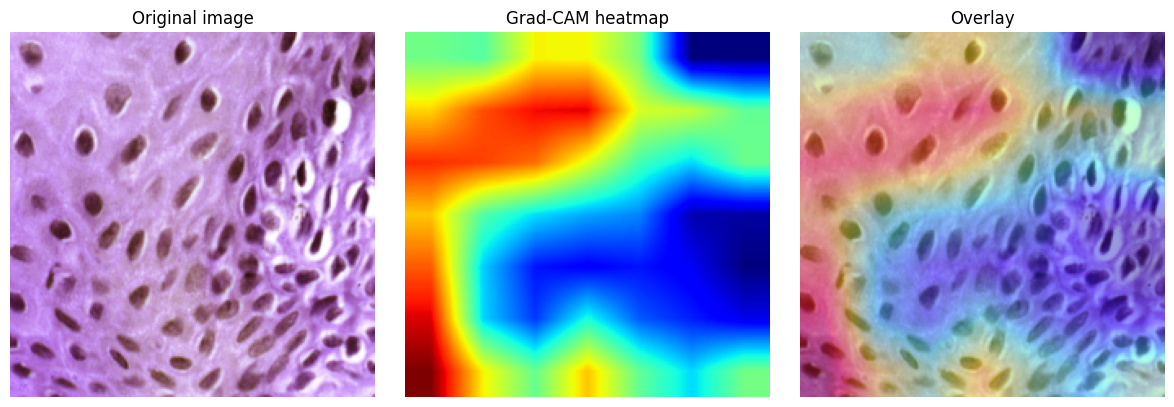

Actual class: Normal
Predicted class: Normal


In [23]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

idx = 0

image_tensor, true_label = test_dataset[idx]
input_tensor = image_tensor.unsqueeze(0).to(device)

activations.clear()
gradients.clear()
model.zero_grad(set_to_none=True)

with torch.enable_grad():
    output = model(input_tensor)
    predicted_label = output.argmax(dim=1).item()
    output[0, predicted_label].backward()

activation = activations[0].detach()
gradient = gradients[0].detach()

weights = gradient.mean(dim=(2, 3), keepdim=True)
cam = (weights * activation).sum(dim=1, keepdim=True)
cam = F.relu(cam)
cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam[0, 0].cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

image = image_tensor.cpu().permute(1, 2, 0).numpy()
mean = np.array(imagenet_mean)
std = np.array(imagenet_std)
image = np.clip(image * std + mean, 0, 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual class:", class_names[true_label])
print("Predicted class:", class_names[predicted_label])

In [24]:
# Find representative examples from the existing test predictions
cases = []

for i, (actual, predicted) in enumerate(zip(all_labels, all_predictions)):
    if actual == class_to_idx["MD-OSCC"] and predicted == class_to_idx["WD-OSCC"]:
        cases.append(("MD-OSCC misclassified as WD-OSCC", i))
        break

for i, (actual, predicted) in enumerate(zip(all_labels, all_predictions)):
    if actual == class_to_idx["OSMF"] and predicted == class_to_idx["OSMF"]:
        cases.append(("Correctly classified OSMF", i))
        break

for i, (actual, predicted) in enumerate(zip(all_labels, all_predictions)):
    if actual == predicted and class_names[actual] not in ["OSMF"]:
        cases.append((f"Correctly classified {class_names[actual]}", i))
        break

print("Selected examples:")
for description, i in cases:
    print(description, "| Test index:", i)

Selected examples:
MD-OSCC misclassified as WD-OSCC | Test index: 1033
Correctly classified OSMF | Test index: 276
Correctly classified Normal | Test index: 0


MD-OSCC misclassified as WD-OSCC | Actual: MD-OSCC | Predicted: WD-OSCC
Correctly classified OSMF | Actual: OSMF | Predicted: OSMF
Correctly classified Normal | Actual: Normal | Predicted: Normal


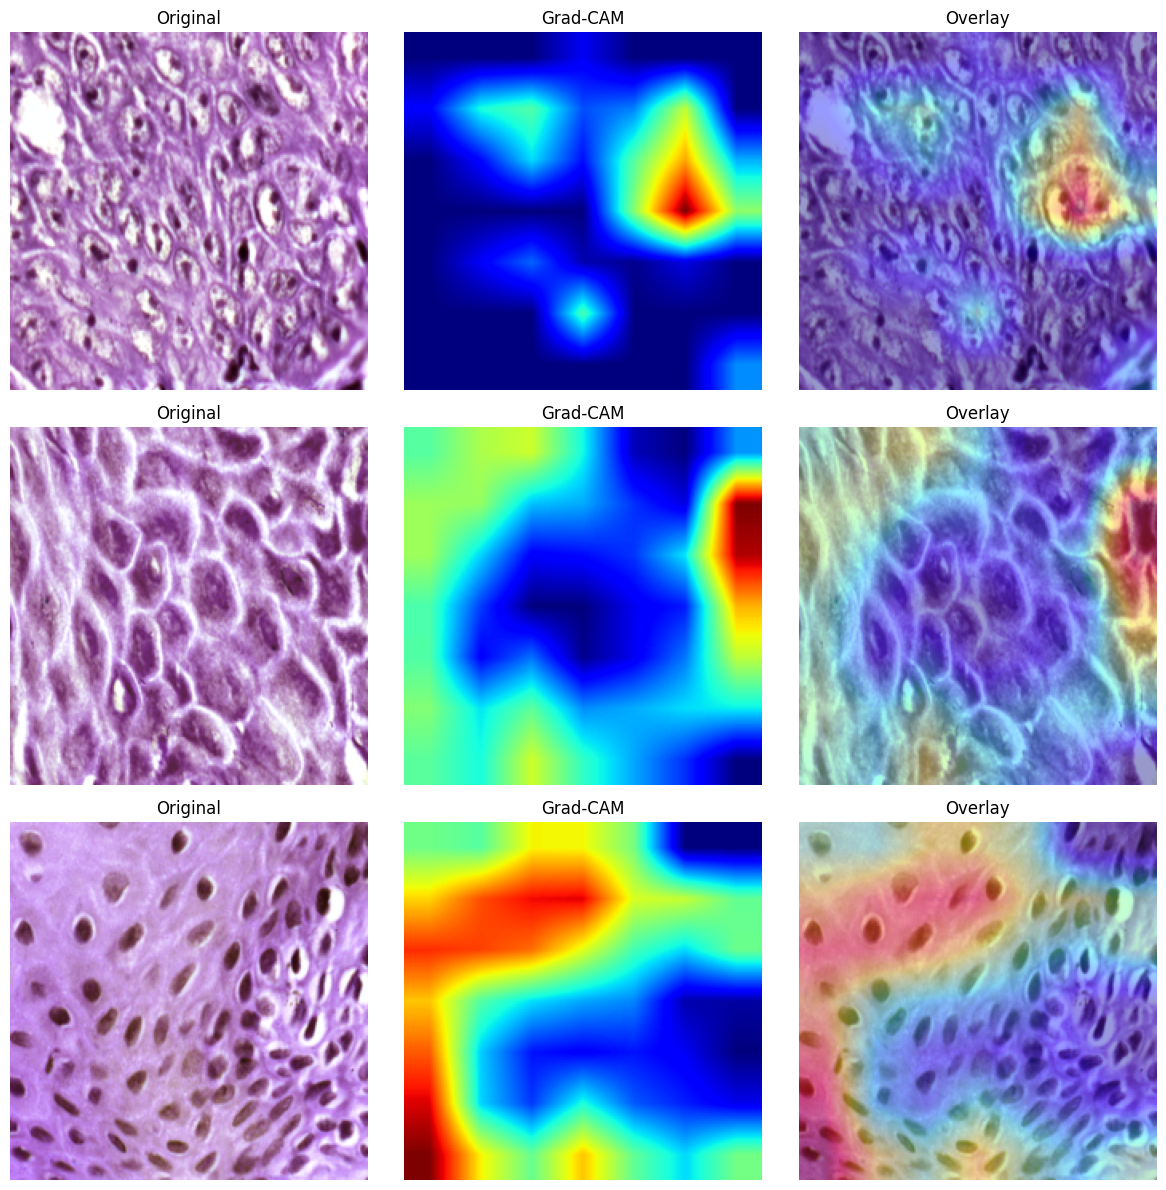

In [25]:
fig, axes = plt.subplots(len(cases), 3, figsize=(12, 4 * len(cases)))

for row_idx, (description, test_idx) in enumerate(cases):
    image_tensor, true_label = test_dataset[test_idx]
    input_tensor = image_tensor.unsqueeze(0).to(device)

    activations.clear()
    gradients.clear()
    model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        output = model(input_tensor)
        predicted_label = output.argmax(dim=1).item()
        output[0, predicted_label].backward()

    activation = activations[0].detach()
    gradient = gradients[0].detach()

    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activation).sum(dim=1, keepdim=True)
    cam = F.relu(cam)
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )[0, 0].cpu().numpy()

    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    image = image_tensor.cpu().permute(1, 2, 0).numpy()
    image = np.clip(image * np.array(imagenet_std) + np.array(imagenet_mean), 0, 1)

    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title("Original")

    axes[row_idx, 1].imshow(cam, cmap="jet")
    axes[row_idx, 1].set_title("Grad-CAM")

    axes[row_idx, 2].imshow(image)
    axes[row_idx, 2].imshow(cam, cmap="jet", alpha=0.4)
    axes[row_idx, 2].set_title("Overlay")

    for ax in axes[row_idx]:
        ax.axis("off")

    print(
        description,
        "| Actual:", class_names[true_label],
        "| Predicted:", class_names[predicted_label]
    )

plt.tight_layout()
plt.show()

In [27]:
#robustness

robustness_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

robustness_dataset = OrchidDataset(test_df, robustness_transform)

robustness_loader = DataLoader(
    robustness_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Original test images:", len(test_dataset))
print("Perturbed test images:", len(robustness_dataset))
print("Same test records:", len(test_dataset) == len(robustness_dataset))

Original test images: 2594
Perturbed test images: 2594
Same test records: True


In [28]:
robustness_labels = []
robustness_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in robustness_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        robustness_predictions.extend(predictions)
        robustness_labels.extend(labels.numpy())

robust_accuracy = accuracy_score(
    robustness_labels, robustness_predictions
)
robust_macro_f1 = f1_score(
    robustness_labels,
    robustness_predictions,
    average="macro"
)
robust_weighted_f1 = f1_score(
    robustness_labels,
    robustness_predictions,
    average="weighted"
)

print("Perturbed test accuracy:", round(robust_accuracy, 4))
print("Perturbed test macro-F1:", round(robust_macro_f1, 4))
print("Perturbed test weighted-F1:", round(robust_weighted_f1, 4))

Perturbed test accuracy: 0.6611
Perturbed test macro-F1: 0.6703
Perturbed test weighted-F1: 0.6527


In [29]:
print("Classification report — perturbed test set")
print(
    classification_report(
        robustness_labels,
        robustness_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix — perturbed test set")
print(
    confusion_matrix(
        robustness_labels,
        robustness_predictions,
        labels=list(range(len(class_names)))
    )
)


Classification report — perturbed test set
              precision    recall  f1-score   support

     MD-OSCC     0.6337    0.4046    0.4939       697
      Normal     0.7967    0.7204    0.7566       397
        OSMF     0.7402    0.8248    0.7802       525
     PD-OSCC     0.6320    0.7670    0.6930       412
     WD-OSCC     0.5645    0.7069    0.6278       563

    accuracy                         0.6611      2594
   macro avg     0.6734    0.6847    0.6703      2594
weighted avg     0.6649    0.6611    0.6527      2594

Confusion matrix — perturbed test set
[[282  12  13 146 244]
 [ 11 286  91   1   8]
 [ 10  44 433   3  35]
 [ 45   9  22 316  20]
 [ 97   8  26  34 398]]


In [30]:
results_summary = pd.DataFrame([
    {
        "experiment": "Original test set",
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(all_labels, all_predictions, average="macro"),
        "weighted_f1": f1_score(all_labels, all_predictions, average="weighted")
    },
    {
        "experiment": "Mild color and brightness perturbation",
        "accuracy": accuracy_score(robustness_labels, robustness_predictions),
        "macro_f1": f1_score(robustness_labels, robustness_predictions, average="macro"),
        "weighted_f1": f1_score(robustness_labels, robustness_predictions, average="weighted")
    }
])

results_summary.to_csv(
    "/kaggle/working/orchid_experiment_summary.csv",
    index=False
)

print(results_summary.round(4).to_string(index=False))
print("\nSaved to /kaggle/working/orchid_experiment_summary.csv")

                            experiment  accuracy  macro_f1  weighted_f1
                     Original test set    0.7001    0.7118       0.6964
Mild color and brightness perturbation    0.6611    0.6703       0.6527

Saved to /kaggle/working/orchid_experiment_summary.csv


In [31]:
from pathlib import Path

output_dir = Path("/kaggle/working")

experiment_results = {
    "original": (all_labels, all_predictions),
    "perturbed": (robustness_labels, robustness_predictions)
}

report_rows = []

for experiment_name, (true_labels, predictions) in experiment_results.items():
    report = classification_report(
        true_labels,
        predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        report_rows.append({
            "experiment": experiment_name,
            "class": class_name,
            **report[class_name]
        })

    matrix = confusion_matrix(
        true_labels,
        predictions,
        labels=list(range(len(class_names)))
    )

    pd.DataFrame(
        matrix,
        index=class_names,
        columns=class_names
    ).to_csv(output_dir / f"orchid_{experiment_name}_confusion_matrix.csv")

pd.DataFrame(report_rows).to_csv(
    output_dir / "orchid_classification_reports.csv",
    index=False
)

print("Saved files:")
for filename in [
    "orchid_classification_reports.csv",
    "orchid_original_confusion_matrix.csv",
    "orchid_perturbed_confusion_matrix.csv"
]:
    print(output_dir / filename)

Saved files:
/kaggle/working/orchid_classification_reports.csv
/kaggle/working/orchid_original_confusion_matrix.csv
/kaggle/working/orchid_perturbed_confusion_matrix.csv


In [32]:
import json
from datetime import datetime, timezone

experiment_config = {
    "project": "ORCHID OSCC Image Classification",
    "model": "EfficientNet-B0",
    "framework": "PyTorch",
    "input_size": [224, 224],
    "num_classes": len(class_names),
    "class_mapping": class_to_idx,
    "random_seed": SEED,
    "split_method": "Patient-independent split",
    "patient_counts": {
        "train": len(train_patients),
        "validation": len(val_patients),
        "test": len(test_patients)
    },
    "image_counts": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    },
    "duplicate_audit": {
        "original_images": 14705,
        "conflicting_duplicate_records_excluded": 306,
        "clean_images": len(clean_metadata)
    },
    "baseline_metrics": {
        "accuracy": round(accuracy_score(all_labels, all_predictions), 4),
        "macro_f1": round(f1_score(all_labels, all_predictions, average="macro"), 4),
        "weighted_f1": round(f1_score(all_labels, all_predictions, average="weighted"), 4)
    },
    "perturbed_metrics": {
        "accuracy": round(accuracy_score(robustness_labels, robustness_predictions), 4),
        "macro_f1": round(f1_score(robustness_labels, robustness_predictions, average="macro"), 4),
        "weighted_f1": round(f1_score(robustness_labels, robustness_predictions, average="weighted"), 4)
    },
    "robustness_test": "One randomized mild brightness, contrast, saturation, and hue perturbation per image",
    "limitations": [
        "Each class corresponds to a different hospital, confounding class and hospital effects.",
        "The robustness test uses one randomized perturbation per image.",
        "Grad-CAM visualizations are qualitative and do not establish clinical validity.",
        "This is an academic experiment, not a clinically validated diagnostic system."
    ],
    "recorded_at_utc": datetime.now(timezone.utc).isoformat()
}

config_path = "/kaggle/working/orchid_experiment_config.json"

with open(config_path, "w") as f:
    json.dump(experiment_config, f, indent=2)

print("Configuration saved:", config_path)
print("Train / validation / test images:",
      len(train_df), len(val_df), len(test_df))
print("Train / validation / test patients:",
      len(train_patients), len(val_patients), len(test_patients))

Configuration saved: /kaggle/working/orchid_experiment_config.json
Train / validation / test images: 9557 2248 2594
Train / validation / test patients: 100 22 24


In [33]:
from pathlib import Path
import torch

checkpoint_path = Path(BEST_CHECKPOINT)

print("Checkpoint exists:", checkpoint_path.is_file())

if checkpoint_path.is_file():
    print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / (1024 * 1024), 2))

    saved_state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint type:", type(saved_state).__name__)
    print("Number of state-dict entries:", len(saved_state))
    print("Model architecture: EfficientNet-B0")
    print("Expected classes:", class_names)
else:
    print("Checkpoint not found. Check BEST_CHECKPOINT.")

Checkpoint exists: True
Checkpoint size (MB): 15.6
Checkpoint type: OrderedDict
Number of state-dict entries: 360
Model architecture: EfficientNet-B0
Expected classes: ['MD-OSCC', 'Normal', 'OSMF', 'PD-OSCC', 'WD-OSCC']


In [34]:
from pathlib import Path
import zipfile

output_dir = Path("/kaggle/working")

files_to_package = [
    "orchid_experiment_best.pth",
    "orchid_experiment_summary.csv",
    "orchid_classification_reports.csv",
    "orchid_original_confusion_matrix.csv",
    "orchid_perturbed_confusion_matrix.csv",
    "orchid_experiment_config.json"
]

zip_path = output_dir / "orchid_final_experiment_package.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_package:
        file_path = output_dir / filename
        if file_path.is_file():
            zipf.write(file_path, arcname=filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

print("\nPackage:", zip_path)
print("Package size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

Added: orchid_experiment_best.pth
Added: orchid_experiment_summary.csv
Added: orchid_classification_reports.csv
Added: orchid_original_confusion_matrix.csv
Added: orchid_perturbed_confusion_matrix.csv
Added: orchid_experiment_config.json

Package: /kaggle/working/orchid_final_experiment_package.zip
Package size (MB): 14.39


In [35]:
import zipfile
from pathlib import Path

zip_path = Path("/kaggle/working/orchid_final_experiment_package.zip")

with zipfile.ZipFile(zip_path, "r") as zipf:
    contents = zipf.namelist()
    print("Files inside package:")
    for name in contents:
        print("-", name)

    print("\nTotal files:", len(contents))
    print("ZIP integrity:", "OK" if zipf.testzip() is None else "FAILED")

Files inside package:
- orchid_experiment_best.pth
- orchid_experiment_summary.csv
- orchid_classification_reports.csv
- orchid_original_confusion_matrix.csv
- orchid_perturbed_confusion_matrix.csv
- orchid_experiment_config.json

Total files: 6
ZIP integrity: OK


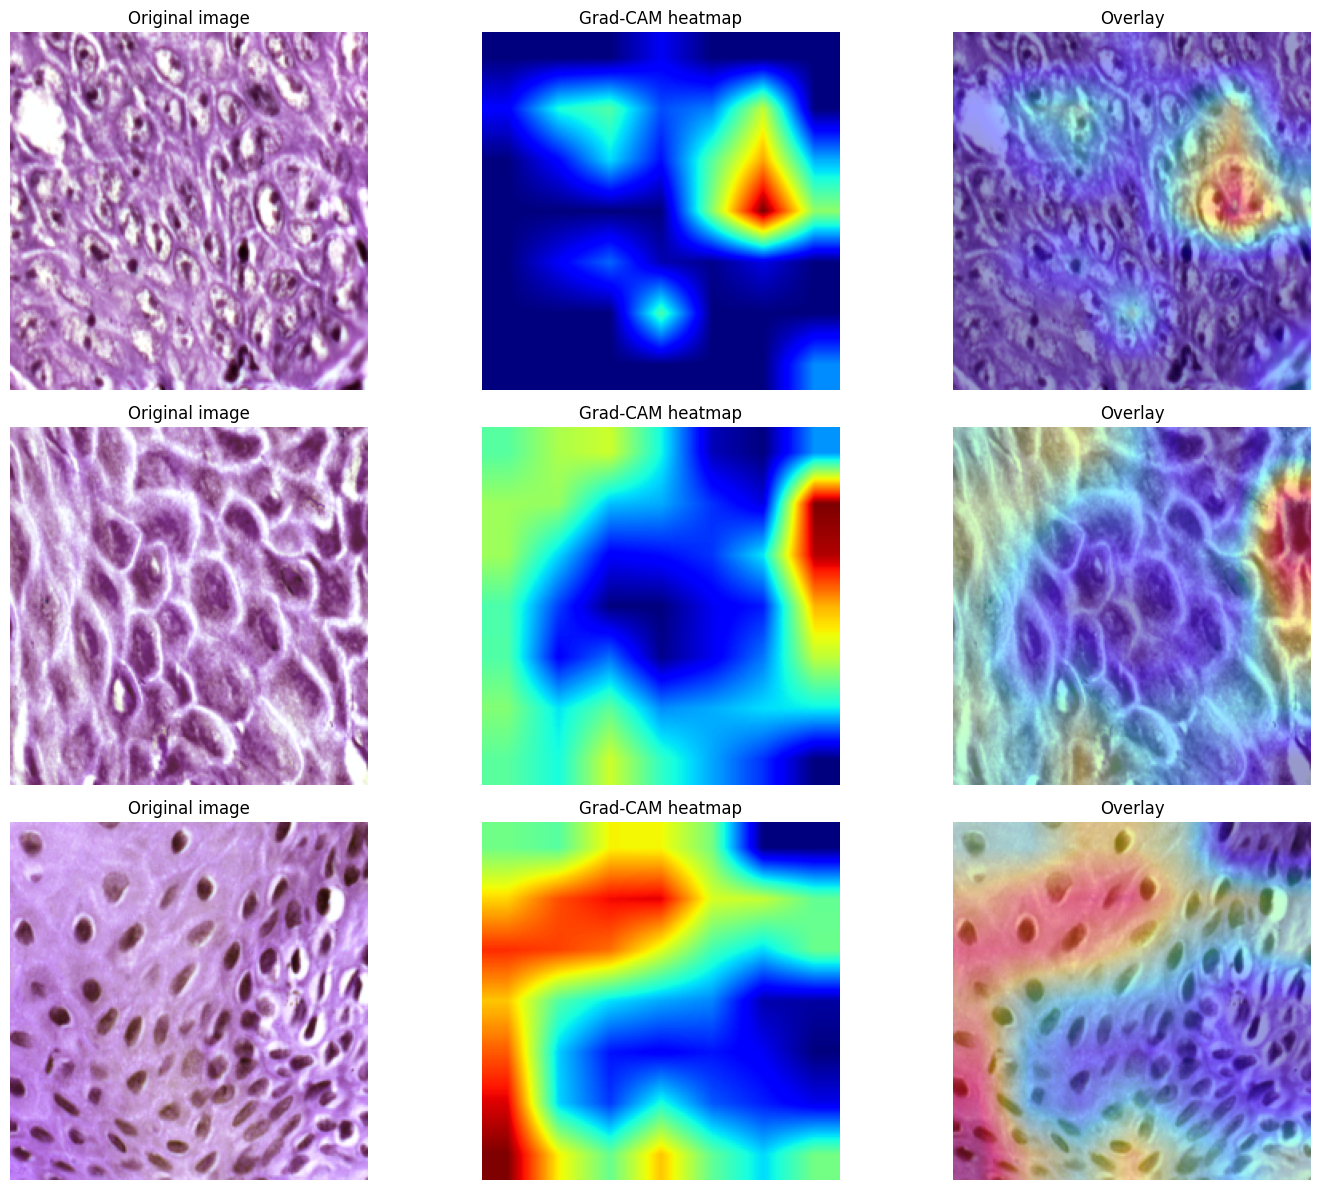

Saved: /kaggle/working/orchid_gradcam_examples.png


In [36]:
fig, axes = plt.subplots(len(cases), 3, figsize=(15, 12))

for row_idx, (description, test_idx) in enumerate(cases):
    image_tensor, true_label = test_dataset[test_idx]
    input_tensor = image_tensor.unsqueeze(0).to(device)

    activations.clear()
    gradients.clear()
    model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        output = model(input_tensor)
        predicted_label = output.argmax(dim=1).item()
        output[0, predicted_label].backward()

    activation = activations[0].detach()
    gradient = gradients[0].detach()

    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )[0, 0].cpu().numpy()

    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    image = image_tensor.cpu().permute(1, 2, 0).numpy()
    image = np.clip(
        image * np.array(imagenet_std) + np.array(imagenet_mean),
        0, 1
    )

    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title("Original image")

    axes[row_idx, 1].imshow(cam, cmap="jet")
    axes[row_idx, 1].set_title("Grad-CAM heatmap")

    axes[row_idx, 2].imshow(image)
    axes[row_idx, 2].imshow(cam, cmap="jet", alpha=0.4)
    axes[row_idx, 2].set_title("Overlay")

    for ax in axes[row_idx]:
        ax.axis("off")

    axes[row_idx, 0].set_ylabel(
        f"Actual: {class_names[true_label]}\nPredicted: {class_names[predicted_label]}",
        fontsize=10
    )

plt.tight_layout()
fig.savefig(
    "/kaggle/working/orchid_gradcam_examples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: /kaggle/working/orchid_gradcam_examples.png")

In [39]:
from pathlib import Path
import zipfile

output_dir = Path("/kaggle/working")

files_to_package = [
    "orchid_experiment_best.pth",
    "orchid_experiment_summary.csv",
    "orchid_classification_reports.csv",
    "orchid_original_confusion_matrix.csv",
    "orchid_perturbed_confusion_matrix.csv",
    "orchid_experiment_config.json",
    "orchid_gradcam_examples.png",
    "orchid_methodology.json"
]

zip_path = output_dir / "orchid_final_experiment_package.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_package:
        file_path = output_dir / filename
        if file_path.is_file():
            zipf.write(file_path, arcname=filename)
            print("Added:", filename)
        else:
            print("MISSING:", filename)

with zipfile.ZipFile(zip_path, "r") as zipf:
    print("\nTotal files:", len(zipf.namelist()))
    print("ZIP integrity:", "OK" if zipf.testzip() is None else "FAILED")

Added: orchid_experiment_best.pth
Added: orchid_experiment_summary.csv
Added: orchid_classification_reports.csv
Added: orchid_original_confusion_matrix.csv
Added: orchid_perturbed_confusion_matrix.csv
Added: orchid_experiment_config.json
Added: orchid_gradcam_examples.png
Added: orchid_methodology.json

Total files: 8
ZIP integrity: OK


In [38]:
methodology = {
    "dataset": "ORCHID OSCC classification dataset",
    "original_image_count": 14705,
    "conflicting_duplicate_records_excluded": 306,
    "clean_image_count": 14399,
    "split_strategy": "Patient-independent split, random seed 42",
    "train_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "train_patients": len(train_patients),
    "validation_patients": len(val_patients),
    "test_patients": len(test_patients),
    "architecture": "EfficientNet-B0",
    "input_resolution": "224x224",
    "classes": class_names,
    "training_augmentation": [
        "Random horizontal flip",
        "Random rotation up to 10 degrees"
    ],
    "evaluation_preprocessing": [
        "Resize to 224x224",
        "Convert to tensor",
        "ImageNet normalization"
    ],
    "interpretability": "Grad-CAM",
    "robustness_experiment": "Mild brightness, contrast, saturation, and hue perturbation",
    "baseline_accuracy": round(accuracy_score(all_labels, all_predictions), 4),
    "baseline_macro_f1": round(f1_score(all_labels, all_predictions, average="macro"), 4),
    "perturbed_accuracy": round(accuracy_score(robustness_labels, robustness_predictions), 4),
    "perturbed_macro_f1": round(f1_score(robustness_labels, robustness_predictions, average="macro"), 4)
}

methodology_path = "/kaggle/working/orchid_methodology.json"

with open(methodology_path, "w") as f:
    json.dump(methodology, f, indent=2)

print("Methodology summary saved:", methodology_path)
print("Train / validation / test images:",
      len(train_df), len(val_df), len(test_df))

Methodology summary saved: /kaggle/working/orchid_methodology.json
Train / validation / test images: 9557 2248 2594
